# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 19: Inference Demo

### Objective

This notebook demonstrates the complete system on real examples:

```text
Input iris -> Preprocessing -> Recognition -> Prediction -> Confidence score -> Nearest matches
```

People the model has **never seen** are enrolled with only a few images each, and held-out images of them (and of strangers who are not enrolled) are identified. For every query the notebook shows the preprocessing stages, the predicted identity or "unknown person", a calibrated confidence, and the nearest enrolled identities with their images. It then measures how the system behaves on the whole held-out set, so the demonstration is backed by numbers.

### Important boundary of this notebook

This notebook **uses** the trained system; it trains and tunes nothing. The decision threshold and the confidence calibration use the **validation** people only. The demo people (test people or the unseen dataset) play no part in any choice.

## 1. Research rationale

### 1.1 The pipeline, stage by stage

| Stage | What happens | Where it comes from |
|---|---|---|
| **Input iris** | A near-infrared eye image | The datasets (Notebook 01) |
| **Preprocessing** | Segmentation (pupil and limbus circles), rubber-sheet normalization to a 64 x 512 strip, enhancement, quality check | Notebooks 02 to 05. For dataset images the **stored outputs** are shown. For a new image a **live approximation** is available (section 1.5) |
| **Recognition** | The strip becomes a 256-d embedding | The **best recognition model** of Notebook 13 |
| **Prediction** | The most similar enrolled identity, or "unknown person" | Cosine similarity to identity prototypes (the mean embedding of an identity's enrolled images) |
| **Confidence score** | Estimated probability that the top match is right | Section 1.4 |
| **Nearest matches** | The top-k enrolled identities with similarities and their enrolled images | Same similarities |

### 1.2 The demo system

The gallery enrols the `K` support images of every demo person, except a fixed share (`STRANGER_FRACTION`) who are **left out** to play strangers. Probes are the held-out query images: probes of enrolled people should be matched, probes of strangers should be rejected. The notebook asserts that the model **never trained on any identity of the demo pool**.

### 1.3 The decision rule

A probe is **accepted** if the similarity of its best match is at least a threshold; otherwise the answer is "unknown person". The threshold is calibrated on the **validation** people with a leave-one-identity-out rule: each validation probe is compared with all validation prototypes **except its own**, and the best of those scores is a "stranger score". The threshold lets at most `TARGET_OPEN_FAR` of these stranger scores through. A larger gallery means more chances for a stranger to resemble someone, so the false-accept rate on the demo gallery can be higher than the target; the batch evaluation (section 9) reports the real value.

### 1.4 The confidence score

On the validation people (closed set, all identities enrolled) a logistic regression is fitted to predict whether the top-1 identity is correct, from two inputs: the **top similarity** and the **margin** (top similarity minus the second best). Its output is the confidence: *the estimated probability that the best match is the right identity, if the person is enrolled*.

- It is **conditional on enrollment**: for a stranger it has no meaning. Next to it the demo shows the **open-set false-accept rate at this similarity** (the share of validation stranger scores at or above it).
- It depends on the **gallery size** (larger galleries lower the real accuracy) and on the **dataset** (a domain shift lowers it).
- Its quality is measured by the expected calibration error (ECE) and a reliability diagram, on the validation people (where it was fitted, so optimistic) and on the demo people (held out).

### 1.5 Preprocessing: stored outputs and the live approximation

- **Stored** (default): for a dataset image, the raw eye, the segmentation circles, the normalized strip, and the enhanced strip (the recognizer's input) are read from the outputs of Notebooks 02 to 05. These are exactly what the model saw.
- **Live** (optional, for a new image): `segment_iris`, `rubber_sheet`, and `enhance_strip` are written from the descriptions of Notebooks 02 to 04, **not** from their code. They are **checked against the stored strips** on dataset images: correlation, embedding similarity, and segmentation error. A verdict says whether the live path is close enough to use. The orientation of the strip (which edge is the pupil, which way the angle runs) is chosen by the best agreement with the stored strips.

### 1.6 Limits

- A demo shows what the system does on a few examples; the **batch evaluation** is the evidence.
- The confidence is calibrated for galleries of about the validation size; for much larger galleries it is optimistic.
- One model, one seed: this is not a significance test (Notebook 18).
- **Windows:** the kernel crash seen earlier comes from NumPy matrix multiplication next to PyTorch; this notebook uses `np.einsum` and a hand-written solver, and imports PyTorch first.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
import math
import textwrap
import warnings
import zlib
from pathlib import Path, PurePosixPath

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import models as tv_models
except ImportError as error:
    raise ImportError(
        "Notebook 19 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

print("Project root:", PROJECT_ROOT)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation


## 4. Configuration

- `QUICK_TEST = True` uses the **quick-test model of Notebook 13** (1-shot) with a few demo queries and writes to a separate folder; the numbers are meaningless, it only checks the code.
- `DEMO_SHOT`: enrolled images per person (the model `best_<K>shot.pt` is used; the nearest available shot if that file is missing). `DEMO_POOL`: `"test"` (unseen people of the source dataset) or `"cross"` (the unseen dataset). `MODEL_PATH` overrides the model file.
- `TARGET_OPEN_FAR`, `STRANGER_FRACTION`, `TOP_K`: the decision rule, the share of strangers, and the number of nearest matches shown (section 1).
- `N_ENROLLED_QUERIES` / `N_STRANGER_QUERIES`: how many demo queries of each kind are drawn (`DEMO_SEED` makes the draw reproducible).
- `RAW_IMAGE_PATH`: a new eye image for the live path (optional). `VALIDATE_LIVE_PREPROCESSING` checks the live preprocessing against the stored strips on `LIVE_VALIDATION_IMAGES` dataset images.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False                  # True = use the quick-test model of Notebook 13, small demo, separate folder
UPSTREAM_FROM_QUICKTEST = QUICK_TEST

# ---- the system ----
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]            # the source dataset (exactly one)
DEMO_SHOT = 3                                       # enrolled images per person
DEMO_POOL = "test"                                  # "test" = unseen people of the source dataset, "cross" = the unseen dataset
MODEL_PATH = None                                   # None = checkpoints/final_recognition/best/best_<DEMO_SHOT>shot.pt
TARGET_SPLITS = ["train", "val", "test"]            # splits of the unseen dataset used as the demo pool
MIN_TARGET_CLASSES = 5
INPUT_HW = (64, 512)
MIXED_PRECISION = True
EMBED_BATCH_SIZE = 128

# ---- decision and confidence ----
TARGET_OPEN_FAR = 0.05              # share of validation stranger scores the threshold lets through
STRANGER_FRACTION = 0.2             # share of the demo people left out of the gallery
TOP_K = 5                           # nearest matches shown
MIN_CALIBRATION_QUERIES = 50
CALIBRATION_BINS = 10

# ---- demo queries ----
N_ENROLLED_QUERIES = 4
N_STRANGER_QUERIES = 2
DEMO_SEED = 7
SHOW_STAGE_IMAGES = True            # raw eye image, circles, and normalized strip from the stored outputs

# ---- optional live preprocessing (section 11) ----
RAW_IMAGE_PATH = None               # e.g. PROJECT_ROOT / "my_eye.png"
VALIDATE_LIVE_PREPROCESSING = True
LIVE_VALIDATION_IMAGES = 20
LIVE_MIN_EMBEDDING_COSINE = 0.90
PUPIL_PERCENTILE = 5.0

FIGURE_DPI = 200

if QUICK_TEST:
    DEMO_SHOT = 1
    TOP_K = 3
    N_ENROLLED_QUERIES, N_STRANGER_QUERIES = 2, 1
    LIVE_VALIDATION_IMAGES = 4
    print("QUICK_TEST is ON: quick-test model, small demo, separate folder. The numbers are meaningless.")

assert len(TRAIN_DATASETS) == 1, "TRAIN_DATASETS must name exactly one source dataset"
assert DEMO_POOL in {"test", "cross"}, "DEMO_POOL must be 'test' or 'cross'"
assert tuple(INPUT_HW) == (64, 512) and TOP_K >= 1 and CALIBRATION_BINS >= 2
assert 0.0 < TARGET_OPEN_FAR < 1.0 and 0.0 < STRANGER_FRACTION < 0.9 and EMBED_BATCH_SIZE >= 1
assert N_ENROLLED_QUERIES >= 1 and N_STRANGER_QUERIES >= 0 and LIVE_VALIDATION_IMAGES >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(MIXED_PRECISION and DEVICE.type == "cuda")

print("Source dataset:", TRAIN_DATASETS[0], "| demo pool:", DEMO_POOL, "| shot:", DEMO_SHOT, "| device:", DEVICE)

Source dataset: CASIA-Iris-Thousand | demo pool: test | shot: 3 | device: cuda


In [4]:
# ============================================================
# 4b. Input and output locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
BEST_DIR = PROJECT_ROOT / "checkpoints" / f"final_recognition{upstream_suffix}" / "best"
QUALITY_SCORES_PATH = PROJECT_ROOT / "results" / "iris_quality_assessment" / "quality_scores.csv"

# outputs
RESULTS_DIR = PROJECT_ROOT / "results" / f"inference_demo{suffix}"
FIG_DIR = RESULTS_DIR / "figures"
for directory in [RESULTS_DIR, FIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Best models (read):", BEST_DIR)
print("Notebook 19 results:", RESULTS_DIR)

Best models (read): E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\final_recognition\best
Notebook 19 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\inference_demo


## 5. Load the dataset, the model file, and the stored preprocessing outputs

- `fewshot_manifest_long.csv` (Notebook 06): the people, their enrolled (`support`) and held-out (`query`) images, and the splits.
- The **best recognition model** of Notebook 13 (`best_<K>shot.pt`).
- Optionally Notebook 05's `quality_scores.csv`, which (as the end of the metadata chain of Notebooks 02 to 05) should carry the raw image path, the pupil and limbus circles, the normalized and enhanced paths, and the quality score. A few-shot image is linked to its row through the last path components of its `source_path`. If the link fails, the stage images are simply skipped.

In [5]:
# ============================================================
# 5. Load the dataset, find the model, link the stored outputs
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\nRun 06_FewShot_Dataset_Creation.ipynb first.")

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})
required_columns = {"shot", "image_id", "dataset", "class_id", "subject_key", "split", "role", "relative_path", "source_path"}
missing = required_columns.difference(long_manifest.columns)
if missing:
    raise ValueError(f"Notebook 06 manifest is missing required columns: {sorted(missing)}")

source_dataset = TRAIN_DATASETS[0]
assert source_dataset in set(long_manifest["dataset"]), f"{source_dataset} is not in the manifest"
target_datasets = [d for d in sorted(long_manifest["dataset"].unique()) if d != source_dataset]
if DEMO_POOL == "cross" and not target_datasets:
    raise RuntimeError("DEMO_POOL = 'cross' needs a dataset other than the source dataset.")

POOLS = {"val": (source_dataset, ["val"]), "test": (source_dataset, ["test"])}
if target_datasets:
    POOLS["cross"] = (target_datasets[0], list(TARGET_SPLITS))


def load_pool(name, shot):
    '''(support rows = enrolled images, query rows = probes) of a pool at this shot.'''
    dataset, splits = POOLS[name]
    rows = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["dataset"] == dataset) & (long_manifest["split"].isin(splits))]
    support, query = rows[rows["role"] == "support"], rows[rows["role"] == "query"]
    if len(support) == 0 or len(query) == 0:
        raise RuntimeError(f"No images for pool '{name}' at {shot}-shot.")
    return support.reset_index(drop=True), query.reset_index(drop=True)


def find_model():
    if MODEL_PATH is not None:
        return Path(MODEL_PATH)
    wanted = BEST_DIR / f"best_{DEMO_SHOT}shot.pt"
    if wanted.exists():
        return wanted
    found = sorted(BEST_DIR.glob("best_*shot.pt")) if BEST_DIR.exists() else []
    if not found:
        raise FileNotFoundError(f"No best model found in {BEST_DIR}. Run 13_Final_Recognition_Model.ipynb first "
                                "(QUICK_TEST reads its quick-test outputs).")
    shot_of = lambda p: int(p.stem.split("_")[1].replace("shot", ""))
    nearest = min(found, key=lambda p: (abs(shot_of(p) - DEMO_SHOT), shot_of(p)))
    print(f"NOTE: {wanted.name} does not exist; using {nearest.name} instead.")
    return nearest


model_path = find_model()
class_dataset = dict(zip(long_manifest["class_id"], long_manifest["dataset"]))

# ---- stored preprocessing outputs (Notebooks 02 to 05), optional ----
STAGE_CIRCLE_KEYS = ["pupil_cx", "pupil_cy", "pupil_radius", "limbus_cx", "limbus_cy", "limbus_radius"]
quality, stage_lookup = None, {}


def path_key(path):
    return "/".join(PurePosixPath(str(path).replace("\\", "/")).parts[-4:]).lower()


if QUALITY_SCORES_PATH.exists():
    quality = pd.read_csv(QUALITY_SCORES_PATH, low_memory=False)
    if "output_path" in quality.columns:
        stage_lookup = {path_key(p): i for i, p in enumerate(quality["output_path"].astype(str))}


def stage_row(source_path):
    '''The metadata row of Notebooks 02 to 05 of a few-shot image, or None if it cannot be linked.'''
    if quality is None or not stage_lookup:
        return None
    index = stage_lookup.get(path_key(source_path))
    return None if index is None else quality.iloc[index]


print("Model file:", model_path)
print("Pools:", {k: v[0] + "/" + "+".join(v[1]) for k, v in POOLS.items()})
print("Stored preprocessing metadata:", f"{len(stage_lookup)} rows linked by path" if stage_lookup else "not available (stage images will be skipped)")

Model file: E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\final_recognition\best\best_3shot.pt
Pools: {'val': 'CASIA-Iris-Thousand/val', 'test': 'CASIA-Iris-Thousand/test', 'cross': 'IITD/train+val+test'}
Stored preprocessing metadata: 22177 rows linked by path


## 6. The recognition model

`EmbeddingNet` and `load_model` are copied from Notebooks 14 and 18 (a backbone followed by a 256-d embedding layer; weights come from the checkpoint, nothing is downloaded). `load_model` keeps the **leakage guard**: the model must have been trained on the source dataset only. `extract_embeddings` returns unit-length embeddings, and `similarity_matrix` builds probe-by-identity cosine similarities with `np.einsum`, as in the evaluation notebooks.

In [6]:
# ============================================================
# 6. Model, embeddings, similarities
# ============================================================

KNOWN_BACKBONES = {"resnet50": (2048, False), "efficientnet_b0": (1280, False), "efficientnet_b3": (1536, False),
                   "efficientnet_v2_s": (1280, False), "convnext_tiny": (768, False), "swin_t": (768, True), "vit_b_16": (768, True)}


def build_backbone(name):
    '''Backbone without pretrained weights (they come from the checkpoint); classification head replaced by the identity.'''
    builder = getattr(tv_models, name, None)
    if builder is None:
        raise ValueError(f"torchvision has no model named '{name}'. Update torchvision.")
    backbone = builder(weights=None)
    if name.startswith("resnet"):
        backbone.fc = nn.Identity()
    elif name.startswith("efficientnet"):
        backbone.classifier = nn.Identity()
    elif name.startswith("convnext"):
        backbone.classifier[2] = nn.Identity()
    elif name.startswith("swin"):
        backbone.head = nn.Identity()
    elif name.startswith("vit"):
        backbone.heads = nn.Identity()
    else:
        raise ValueError(name)
    return backbone, KNOWN_BACKBONES[name][0], KNOWN_BACKBONES[name][1]


class EmbeddingNet(nn.Module):
    def __init__(self, backbone_name, embedding_dim, square_size):
        super().__init__()
        self.backbone, feature_dim, self.needs_square = build_backbone(backbone_name)
        self.square_size = square_size
        self.embed = nn.Sequential(nn.Linear(feature_dim, embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = x.expand(-1, 3, -1, -1)                       # x: float [B, 1, H, W] in [0, 1]
        x = (x - self.mean) / self.std
        if self.needs_square:
            x = F.interpolate(x, size=(self.square_size, self.square_size), mode="bilinear", align_corners=False)
        return self.embed(self.backbone(x))


def torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def load_model(path):
    '''Load a checkpoint, check that it was trained on the source dataset only, return (model in evaluation mode, checkpoint).'''
    checkpoint = torch_load(path)
    for key in ["model_state", "backbone", "embedding_dim", "input_hw", "vit_input_size", "shot", "train_classes"]:
        assert key in checkpoint, f"{Path(path).name}: the checkpoint has no '{key}'"
    assert tuple(checkpoint["input_hw"]) == tuple(INPUT_HW), "the model was trained on a different image size"
    assert checkpoint["backbone"] in KNOWN_BACKBONES, f"unknown backbone '{checkpoint['backbone']}'"

    trained = set(checkpoint["train_classes"])
    seen = {class_dataset.get(c, "UNKNOWN") for c in trained}
    assert "UNKNOWN" not in seen and seen <= {source_dataset}, f"the model was trained on {sorted(seen)}, not only on {source_dataset}"

    net = EmbeddingNet(checkpoint["backbone"], checkpoint["embedding_dim"], checkpoint["vit_input_size"])
    net.load_state_dict(checkpoint["model_state"])
    return net.to(DEVICE).eval(), checkpoint


IMAGE_CACHE = {}


def read_gray_uint8(path):
    key = str(path)
    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)
        if image is None:
            raise ValueError(f"Unable to read image: {key}")
        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)
        IMAGE_CACHE[key] = image
    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree
    source = Path(row.source_path)
    if source.exists():
        return source
    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    return torch.from_numpy(np.stack([read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]))


@torch.no_grad()
def extract_embeddings(net, images_uint8):
    '''L2-normalised embeddings of a uint8 image tensor [N, H, W] (eval mode, as in Notebooks 13 and 14).'''
    net.eval()
    outputs = []
    for start in range(0, len(images_uint8), EMBED_BATCH_SIZE):
        batch = images_uint8[start:start + EMBED_BATCH_SIZE].to(DEVICE).float().div_(255.0).unsqueeze(1)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            embedding = net(batch)
        outputs.append(F.normalize(embedding.float(), dim=1).cpu())
    return torch.cat(outputs).numpy()


def similarity_matrix(support_emb, support_labels, query_emb, query_labels):
    '''Probe-by-identity cosine similarities; prototypes are the normalised mean of each identity's support embeddings.'''
    classes, class_index = np.unique(support_labels, return_inverse=True)
    prototypes = np.zeros((len(classes), support_emb.shape[1]), dtype=np.float64)
    np.add.at(prototypes, class_index, support_emb.astype(np.float64))
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)
    lookup = {label: i for i, label in enumerate(classes)}
    unknown = [label for label in set(query_labels) if label not in lookup]
    if unknown:
        raise ValueError(f"{len(unknown)} query class(es) have no enrolled images")
    own = np.array([lookup[label] for label in query_labels], dtype=np.int64)
    # np.einsum instead of the "@" operator: it never calls the BLAS / OpenMP libraries that can crash the kernel on Windows.
    similarity = np.einsum("qd,cd->qc", query_emb.astype(np.float64), prototypes, optimize=False)
    return similarity, own, classes

## 7. Decision threshold and confidence: functions and tests

| Function | Purpose |
|---|---|
| `top_two` | The best and second-best similarity of every probe |
| `stranger_scores` | The best similarity over all identities **except the probe's own** (a probe acting as a stranger) |
| `far_threshold` | The lowest threshold at which at most a share `far` of the scores pass (same as Notebook 14) |
| `open_far_at` | The share of stranger scores at or above a similarity |
| `solve_small`, `fit_logistic` | A logistic regression (Newton's method with a small ridge) with a **hand-written linear solver**, so no LAPACK or BLAS is involved |
| `expected_calibration_error` | Weighted average gap between predicted confidence and observed accuracy over equal-width bins |

The next cell tests all of them on cases with known answers.

In [7]:
# ============================================================
# 7. Decision threshold and confidence: functions and tests
# ============================================================

def top_two(similarity):
    n_classes = similarity.shape[1]
    assert n_classes >= 2, "at least two enrolled identities are needed"
    part = np.partition(similarity, n_classes - 2, axis=1)
    return part[:, n_classes - 1], part[:, n_classes - 2]


def stranger_scores(similarity, own):
    masked = similarity.copy()
    masked[np.arange(len(own)), own] = -np.inf
    return masked.max(axis=1)


def far_threshold(scores, far):
    '''Lowest threshold t such that at most a fraction `far` of the scores are >= t.'''
    ordered = np.sort(np.asarray(scores, dtype=np.float64))[::-1]
    if len(ordered) == 0:
        return float("nan")
    allowed = int(math.floor(far * len(ordered)))
    return float(ordered[-1]) if allowed >= len(ordered) else float(np.nextafter(ordered[allowed], np.inf))


def open_far_at(values, sorted_scores):
    '''Share of the stranger scores (ascending) that are >= each value.'''
    values = np.asarray(values, dtype=np.float64)
    return 1.0 - np.searchsorted(sorted_scores, values, side="left") / len(sorted_scores)


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30.0, 30.0)))


def solve_small(A, b):
    '''Gaussian elimination with partial pivoting for a small linear system.'''
    n = len(b)
    M = [[float(v) for v in A[i]] + [float(b[i])] for i in range(n)]
    for col in range(n):
        pivot = max(range(col, n), key=lambda r: abs(M[r][col]))
        if abs(M[pivot][col]) < 1e-14:
            raise ValueError("singular matrix")
        M[col], M[pivot] = M[pivot], M[col]
        for r in range(col + 1, n):
            factor = M[r][col] / M[col][col]
            for c in range(col, n + 1):
                M[r][c] -= factor * M[col][c]
    x = [0.0] * n
    for r in range(n - 1, -1, -1):
        x[r] = (M[r][n] - sum(M[r][c] * x[c] for c in range(r + 1, n))) / M[r][r]
    return np.array(x)


def fit_logistic(X, y, ridge=1e-3, iterations=60):
    '''Logistic regression by Newton's method; X: [n, d] with a leading column of ones, y in {0, 1}; no penalty on the intercept.'''
    d = X.shape[1]
    penalty = np.full(d, ridge)
    penalty[0] = 0.0
    w = np.zeros(d)
    for _ in range(iterations):
        p = sigmoid(np.einsum("ni,i->n", X, w))
        gradient = np.einsum("ni,n->i", X, p - y) + penalty * w
        weight = np.maximum(p * (1.0 - p), 1e-9)
        hessian = np.einsum("ni,n,nj->ij", X, weight, X) + np.diag(penalty)
        step = solve_small(hessian, gradient)
        w = w - step
        if float(np.max(np.abs(step))) < 1e-9:
            break
    return w


def expected_calibration_error(p, y, bins):
    '''(ECE, reliability rows) with equal-width confidence bins.'''
    p, y = np.asarray(p, dtype=float), np.asarray(y, dtype=float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    index = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    ece, rows = 0.0, []
    for b in range(bins):
        mask = index == b
        if mask.any():
            ece += float(mask.mean()) * abs(float(p[mask].mean()) - float(y[mask].mean()))
            rows.append((float(edges[b]), float(edges[b + 1]), float(p[mask].mean()), float(y[mask].mean()), int(mask.sum())))
    return float(ece), rows


# ---- tests ----
sim_t = np.array([[0.9, 0.5, 0.1], [0.2, 0.6, 0.7]])
t1, t2 = top_two(sim_t)
assert np.allclose(t1, [0.9, 0.7]) and np.allclose(t2, [0.5, 0.6])
assert np.allclose(stranger_scores(sim_t, np.array([0, 1])), [0.5, 0.7]), "the own identity must be excluded"

scores_t = np.arange(1, 11) / 10.0
thr_t = far_threshold(scores_t, 0.2)
assert int((scores_t >= thr_t).sum()) == 2 and thr_t > 0.8 and int((scores_t >= far_threshold(scores_t, 0.0)).sum()) == 0
assert np.allclose(open_far_at([0.3, 0.05, 0.5], np.array([0.1, 0.2, 0.3, 0.4])), [0.5, 1.0, 0.0])

assert np.allclose(solve_small([[2, 1, 0], [1, 3, 1], [0, 1, 4]], [4, 10, 14]), [1, 2, 3])
assert np.allclose(solve_small([[0, 1], [1, 0]], [2, 3]), [3, 2]), "partial pivoting"
try:
    solve_small([[1, 2], [2, 4]], [1, 2])
    raise AssertionError("a singular system must raise")
except ValueError:
    pass

rng_t = np.random.default_rng(0)
feat = rng_t.normal(size=(20000, 2))
X_t = np.column_stack([np.ones(20000), feat])
true_w = np.array([-0.5, 1.5, 0.7])
y_t = (rng_t.uniform(size=20000) < sigmoid(np.einsum("ni,i->n", X_t, true_w))).astype(float)
assert float(np.max(np.abs(fit_logistic(X_t, y_t) - true_w))) < 0.12, "the logistic fit does not recover the true weights"
X_sep = np.column_stack([np.ones(40), np.repeat([-1.0, 1.0], 20)])
w_sep = fit_logistic(X_sep, np.repeat([0.0, 1.0], 20))
assert np.isfinite(w_sep).all() and sigmoid(w_sep[0] + w_sep[1]) > 0.99, "perfectly separated data must give finite weights"

assert abs(expected_calibration_error([1, 1, 0, 0], [1, 1, 0, 0], 10)[0]) < 1e-12
assert abs(expected_calibration_error(np.full(10, 0.9), [1, 0] * 5, 10)[0] - 0.4) < 1e-12

print("Decision and confidence self-tests passed.")

Decision and confidence self-tests passed.


## 8. Calibration, the gallery, and the prediction function

- `calibrate(model, trained)` runs the **validation people** as a closed set: top similarity, margin, correctness, stranger scores; it fixes the decision **threshold** and fits the **confidence** (section 1.4).
- `build_demo_system(model, shot, trained)` loads the demo pool, **asserts that the model never trained on any of its identities**, leaves a fixed share of the people out as strangers, and enrolls the others (prototypes from their `K` support images).
- `predict_embeddings` turns probe embeddings into predictions: the ranked identities with similarities, the top similarity, the margin, the confidence, the open-set false-accept rate at this similarity, and the decision.

In [8]:
# ============================================================
# 8. Calibration, gallery, prediction
# ============================================================

def calibrate(net, trained):
    support, query = load_pool("val", SHOT)
    assert not (trained & (set(support["class_id"]) | set(query["class_id"]))), "the model trained on a validation identity"
    sim, own, classes = similarity_matrix(extract_embeddings(net, load_image_tensor(support)), support["class_id"].to_numpy(),
                                          extract_embeddings(net, load_image_tensor(query)), query["class_id"].to_numpy())
    top1, top2 = top_two(sim)
    margin = top1 - top2
    correct = (sim.argmax(axis=1) == own).astype(np.float64)
    strangers = stranger_scores(sim, own)

    mu = np.array([top1.mean(), margin.mean()])
    sd = np.maximum(np.array([top1.std(), margin.std()]), 1e-6)
    design = np.stack([np.ones(len(top1)), (top1 - mu[0]) / sd[0], (margin - mu[1]) / sd[1]], axis=1)
    weights = fit_logistic(design, correct)
    probability = sigmoid(np.einsum("ni,i->n", design, weights))
    ece, reliability = expected_calibration_error(probability, correct, CALIBRATION_BINS)

    return {"threshold": far_threshold(strangers, TARGET_OPEN_FAR), "mu": mu, "sd": sd, "w": weights,
            "n_identities": len(classes), "n_queries": len(top1), "accuracy": float(correct.mean()), "ece": ece, "reliability": reliability,
            "top1": top1, "correct": correct, "stranger_scores": strangers, "stranger_sorted": np.sort(strangers), "probability": probability}


def confidence_from(top1, margin, cal):
    top1, margin = np.atleast_1d(np.asarray(top1, dtype=float)), np.atleast_1d(np.asarray(margin, dtype=float))
    design = np.stack([np.ones(len(top1)), (top1 - cal["mu"][0]) / cal["sd"][0], (margin - cal["mu"][1]) / cal["sd"][1]], axis=1)
    return sigmoid(np.einsum("ni,i->n", design, cal["w"]))


def build_demo_system(net, trained):
    support, query = load_pool(DEMO_POOL, SHOT)
    pool_classes = set(support["class_id"]) | set(query["class_id"])
    assert not (trained & pool_classes), "the model trained on an identity of the demo pool: the demo would not show unseen people"

    all_classes = sorted(support["class_id"].unique())
    if DEMO_POOL == "cross" and len(all_classes) < MIN_TARGET_CLASSES:
        raise RuntimeError("the unseen dataset has too few identities at this shot")
    order = sorted(all_classes, key=lambda c: (zlib.crc32(f"{DEMO_SEED}|{c}".encode("utf-8")), c))
    n_strangers = max(1, int(round(STRANGER_FRACTION * len(order))))
    stranger_classes = set(order[:n_strangers])
    enrolled = [c for c in all_classes if c not in stranger_classes]
    assert len(enrolled) >= 2, "at least two enrolled identities are needed"

    support_images, query_images = load_image_tensor(support), load_image_tensor(query)
    emb_support, emb_query = extract_embeddings(net, support_images), extract_embeddings(net, query_images)

    in_gallery = support["class_id"].isin(set(enrolled)).to_numpy()
    index = {c: i for i, c in enumerate(enrolled)}
    prototypes = np.zeros((len(enrolled), emb_support.shape[1]), dtype=np.float64)
    np.add.at(prototypes, np.array([index[c] for c in support.loc[in_gallery, "class_id"]]), emb_support[in_gallery].astype(np.float64))
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)

    support_index = {c: np.flatnonzero((support["class_id"] == c).to_numpy()).tolist() for c in all_classes}
    return {"support": support, "query": query, "support_images": support_images, "query_images": query_images,
            "emb_query": emb_query, "enrolled": enrolled, "strangers": stranger_classes, "prototypes": prototypes,
            "support_index": support_index}


def predict_embeddings(emb, sys_, cal, top_k=None):
    '''Predictions for unit-length probe embeddings [Q, D]. Returns (list of dicts, similarity matrix [Q, C]).'''
    k = min(TOP_K if top_k is None else top_k, len(sys_["enrolled"]))
    sim = np.einsum("qd,cd->qc", np.asarray(emb, dtype=np.float64), sys_["prototypes"], optimize=False)
    order = np.argsort(-sim, axis=1, kind="stable")[:, :k]
    top1, top2 = top_two(sim)
    margin = top1 - top2
    confidence = confidence_from(top1, margin, cal)
    open_far = open_far_at(top1, cal["stranger_sorted"])
    out = []
    for q in range(len(sim)):
        accepted = bool(top1[q] >= cal["threshold"])
        classes = [sys_["enrolled"][j] for j in order[q]]
        out.append({"classes": classes, "sims": [float(sim[q, j]) for j in order[q]], "top1": float(top1[q]), "margin": float(margin[q]),
                    "confidence": float(confidence[q]), "open_far": float(open_far[q]), "accepted": accepted,
                    "predicted": classes[0] if accepted else None})
    return out, sim

In [9]:
# ============================================================
# 8b. Load the model, calibrate, build the demo system
# ============================================================

model, checkpoint = load_model(model_path)
SHOT = int(checkpoint["shot"])
if SHOT not in set(long_manifest["shot"]):
    raise RuntimeError(f"The model is for {SHOT}-shot, which does not exist in the manifest.")
trained_classes = set(checkpoint["train_classes"])

cal = calibrate(model, trained_classes)
system = build_demo_system(model, trained_classes)

summary = pd.DataFrame([
    ("model", model_path.name), ("backbone / loss", f"{checkpoint['backbone']} / {checkpoint.get('loss_variant', 'arcface')}"),
    ("enrolled images per person (shot)", SHOT), ("demo pool", f"{POOLS[DEMO_POOL][0]} ({DEMO_POOL})"),
    ("enrolled identities / strangers", f"{len(system['enrolled'])} / {len(system['strangers'])}"),
    ("probes in the pool", len(system["query"])),
    ("calibration people (validation)", f"{cal['n_identities']} identities, {cal['n_queries']} probes"),
    ("validation Rank-1 (closed set)", f"{cal['accuracy']:.3f}"),
    ("decision threshold (cosine)", f"{cal['threshold']:.3f}  (lets {TARGET_OPEN_FAR:.0%} of validation stranger scores through)"),
    ("confidence fit (intercept, similarity, margin)", np.round(cal["w"], 3).tolist()),
    ("calibration error on the fitted data (ECE)", f"{cal['ece']:.3f}"),
], columns=["item", "value"])
display(summary)

if cal["n_queries"] < MIN_CALIBRATION_QUERIES:
    print(f"WARNING: only {cal['n_queries']} validation probes for the calibration (fewer than {MIN_CALIBRATION_QUERIES}); the confidence is unreliable.")

,item,value
0,model,best_3shot.pt
1,backbone / loss,efficientnet_b0 / arcface_triplet_center
2,enrolled images per person (shot),3
3,demo pool,CASIA-Iris-Thousand (test)
4,enrolled identities / strangers,313 / 78
5,probes in the pool,1714
6,calibration people (validation),"196 identities, 858 probes"
7,validation Rank-1 (closed set),0.800
8,decision threshold (cosine),0.397 (lets 5% of validation stranger scores ...
9,"confidence fit (intercept, similarity, margin)","[5.901, 2.028, 3.734]"


## 9. One query through the whole pipeline

`show_pipeline` draws everything for one query:

- **Top row:** the input iris image with the segmentation circles (pupil cyan, limbus green), the preprocessing output (normalized strip, then the enhanced strip that the recognizer sees), and a result panel (prediction, similarity, threshold, margin, confidence, open-set false-accept rate).
- **Below:** the `TOP_K` nearest enrolled identities, each with its enrolled images and a bar of its similarity (red line = decision threshold). A green label marks the true identity when it is known.

For dataset images the raw eye, circles, and normalized strip are read from the stored outputs of Notebooks 02 to 05 (if they could be linked); the enhanced strip is always the recognizer's real input.

In [10]:
# ============================================================
# 9. The pipeline figure
# ============================================================

def strip_stack(strips, gap=6):
    parts = []
    for i, strip in enumerate(strips):
        parts.append(strip)
        if i < len(strips) - 1:
            parts.append(np.full((gap, strip.shape[1]), 128, dtype=np.uint8))
    return np.vstack(parts)


def finite_float(value):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return None
    return value if np.isfinite(value) else None


def stage_context(source_path, strip):
    '''(raw eye image, circles, strips to show, metadata row) of a dataset image from the stored outputs of Notebooks 02 to 05.'''
    info = stage_row(source_path) if SHOW_STAGE_IMAGES else None
    raw, circles, strips = None, [], []

    if info is not None:
        original = info.get("original_path")
        if isinstance(original, str) and Path(original).exists():
            raw = cv2.imread(original, cv2.IMREAD_GRAYSCALE)
        for prefix, color in (("pupil", "cyan"), ("limbus", "lime")):
            values = [finite_float(info.get(f"{prefix}_{k}")) for k in ("cx", "cy", "radius")]
            if all(v is not None for v in values):
                circles.append((*values, color))
        normalized = info.get("normalized_path")
        if isinstance(normalized, str) and Path(normalized).exists():
            image = cv2.imread(normalized, cv2.IMREAD_GRAYSCALE)
            if image is not None:
                strips.append(("normalized strip (Notebook 03)", cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)))

    strips.append(("enhanced strip = recognizer input", strip))
    return raw, circles, strips, info


def show_pipeline(title, raw, circles, strips, prediction, truth_class, truth_note, name):
    k = len(prediction["classes"])
    fig = plt.figure(figsize=(17, 3.0 + 1.1 * k))
    gs = GridSpec(1 + k, 3, figure=fig, width_ratios=[1.3, 3.2, 1.7], height_ratios=[2.6] + [1.0] * k, hspace=0.5, wspace=0.12)

    ax = fig.add_subplot(gs[0, 0])
    if raw is not None:
        ax.imshow(raw, cmap="gray")
        for cx, cy, r, color in circles:
            ax.add_patch(plt.Circle((cx, cy), r, fill=False, color=color, linewidth=1.3))
        ax.set_title("Input iris + segmentation", fontsize=8)
    else:
        ax.text(0.5, 0.5, "raw eye image\nnot available", ha="center", va="center", fontsize=8)
        ax.set_title("Input iris", fontsize=8)
    ax.axis("off")

    ax = fig.add_subplot(gs[0, 1])
    ax.imshow(strip_stack([s for _, s in strips]), cmap="gray", vmin=0, vmax=255, aspect="auto")
    y = 0
    for label, s in strips:
        ax.text(6, y + 10, label, color="yellow", fontsize=7, bbox=dict(facecolor="black", alpha=0.6, pad=1, edgecolor="none"))
        y += s.shape[0] + 6
    ax.set_title("Preprocessing output", fontsize=8)
    ax.axis("off")

    ax = fig.add_subplot(gs[0, 2])
    ax.axis("off")
    decision = f"MATCH  {prediction['predicted']}" if prediction["accepted"] else "UNKNOWN PERSON (below threshold)"
    lines = [f"Ground truth : {truth_note}", f"Prediction   : {decision}",
             f"Similarity   : {prediction['top1']:.3f}  (threshold {cal['threshold']:.3f})", f"Margin to #2 : {prediction['margin']:.3f}",
             f"Confidence   : {100 * prediction['confidence']:.1f}%", "  (chance the top match is right,", "   if the person is enrolled)",
             f"Strangers this similar: {100 * prediction['open_far']:.1f}%"]
    ax.text(0.0, 1.0, "\n".join(lines), va="top", family="monospace", fontsize=8,
            color="green" if prediction["accepted"] else "firebrick")

    for i in range(k):
        cls, sim = prediction["classes"][i], prediction["sims"][i]
        is_true = truth_class is not None and cls == truth_class
        ax_t = fig.add_subplot(gs[1 + i, 0])
        ax_t.axis("off")
        ax_t.text(0.0, 0.5, f"#{i + 1}  {cls}\nsimilarity {sim:.3f}" + ("\n(the true identity)" if is_true else ""), va="center",
                  fontsize=8, color="green" if is_true else "black")
        ax_i = fig.add_subplot(gs[1 + i, 1])
        shown = system["support_index"][cls][:2]
        ax_i.imshow(strip_stack([system["support_images"][j].numpy() for j in shown]), cmap="gray", vmin=0, vmax=255, aspect="auto")
        ax_i.axis("off")
        if i == 0:
            ax_i.set_title("Nearest enrolled identities (their enrolled images)", fontsize=8)
        ax_b = fig.add_subplot(gs[1 + i, 2])
        ax_b.barh([0], [sim], color="green" if is_true else "tab:blue")
        ax_b.axvline(cal["threshold"], color="red", linestyle="--")
        ax_b.set_xlim(min(-0.1, sim - 0.05), 1.0)
        ax_b.set_yticks([])
        if i == 0:
            ax_b.set_title("cosine similarity (red = threshold)", fontsize=8)

    fig.suptitle(title, fontsize=10)
    fig.savefig(FIG_DIR / f"{name}.png", dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

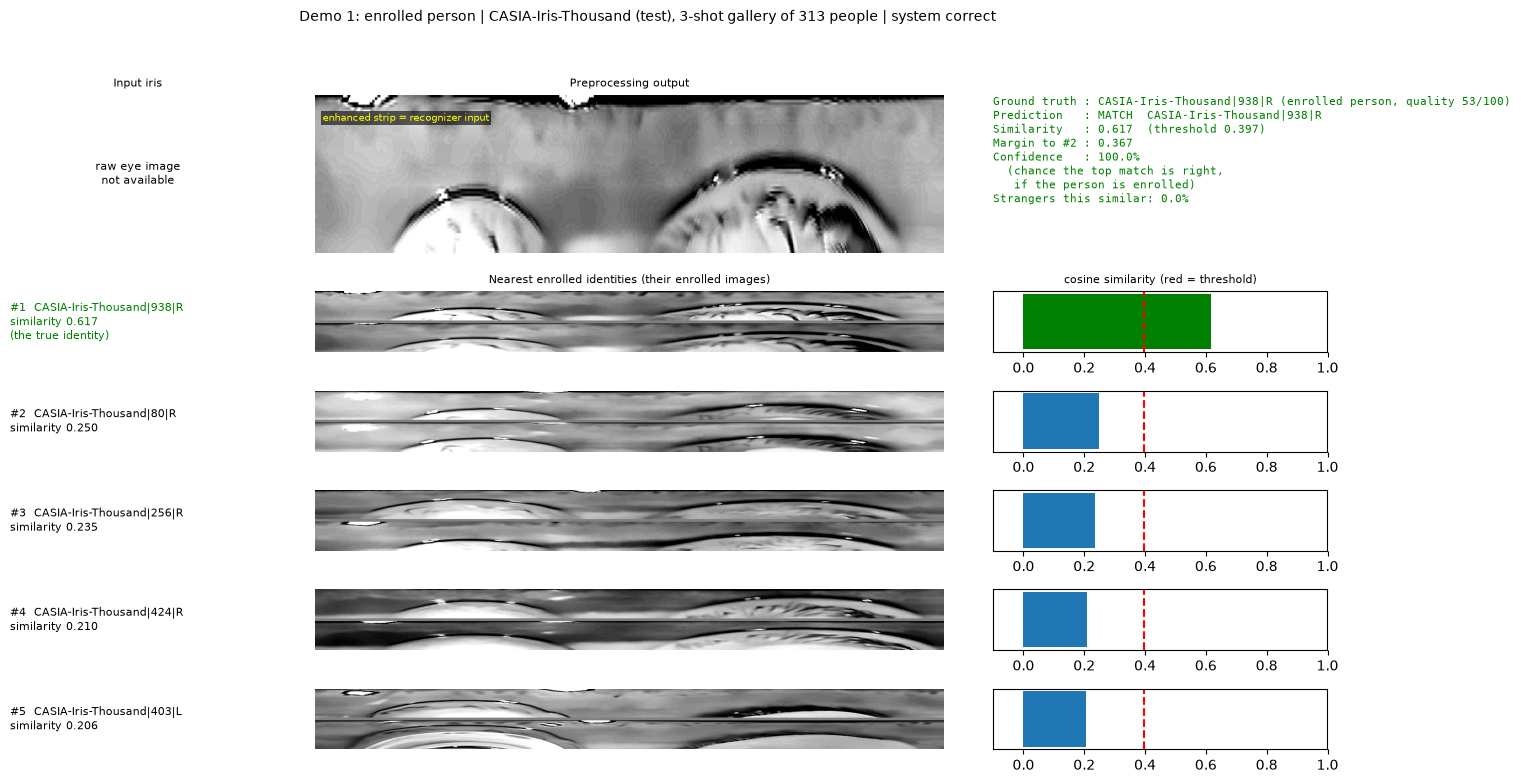

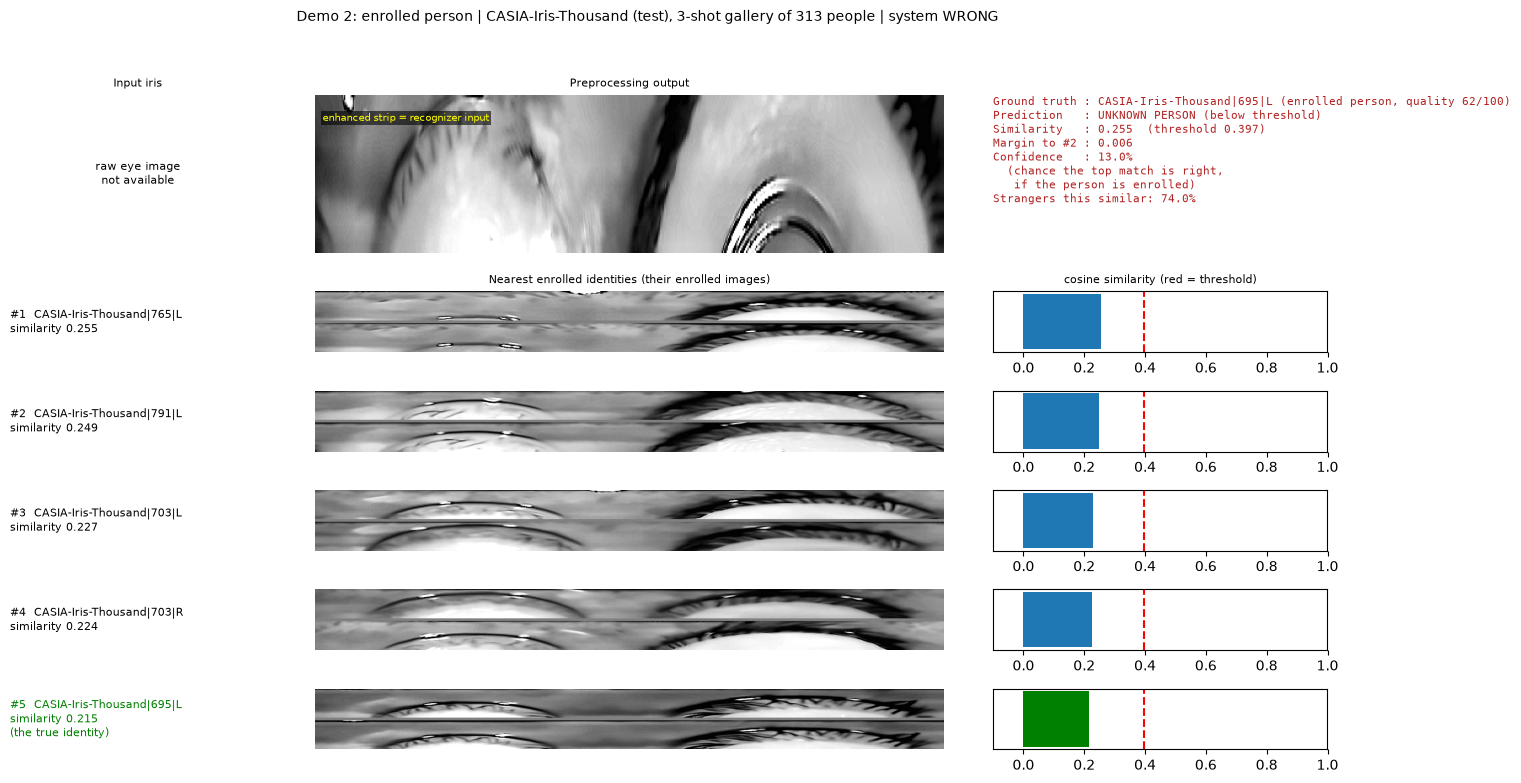

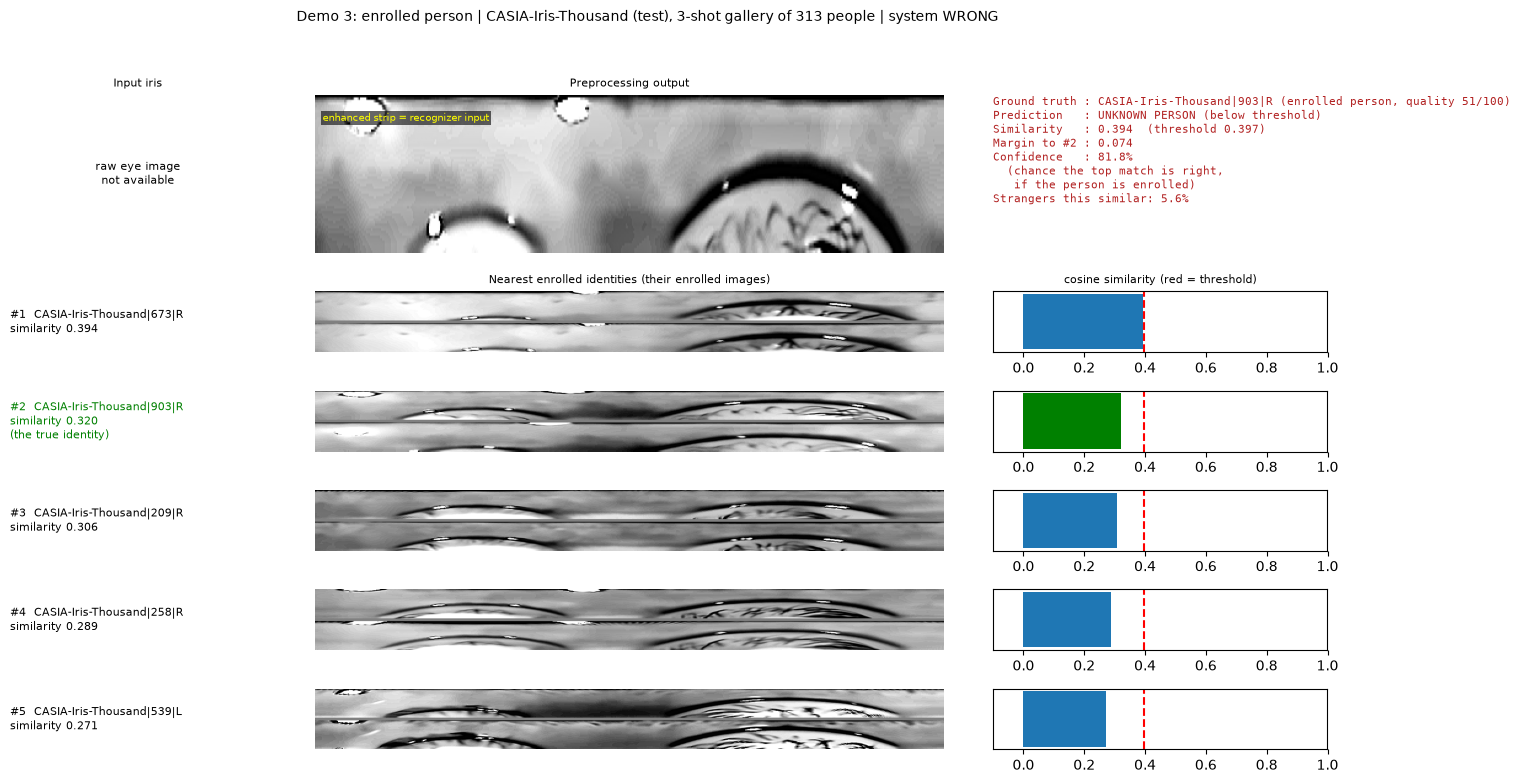

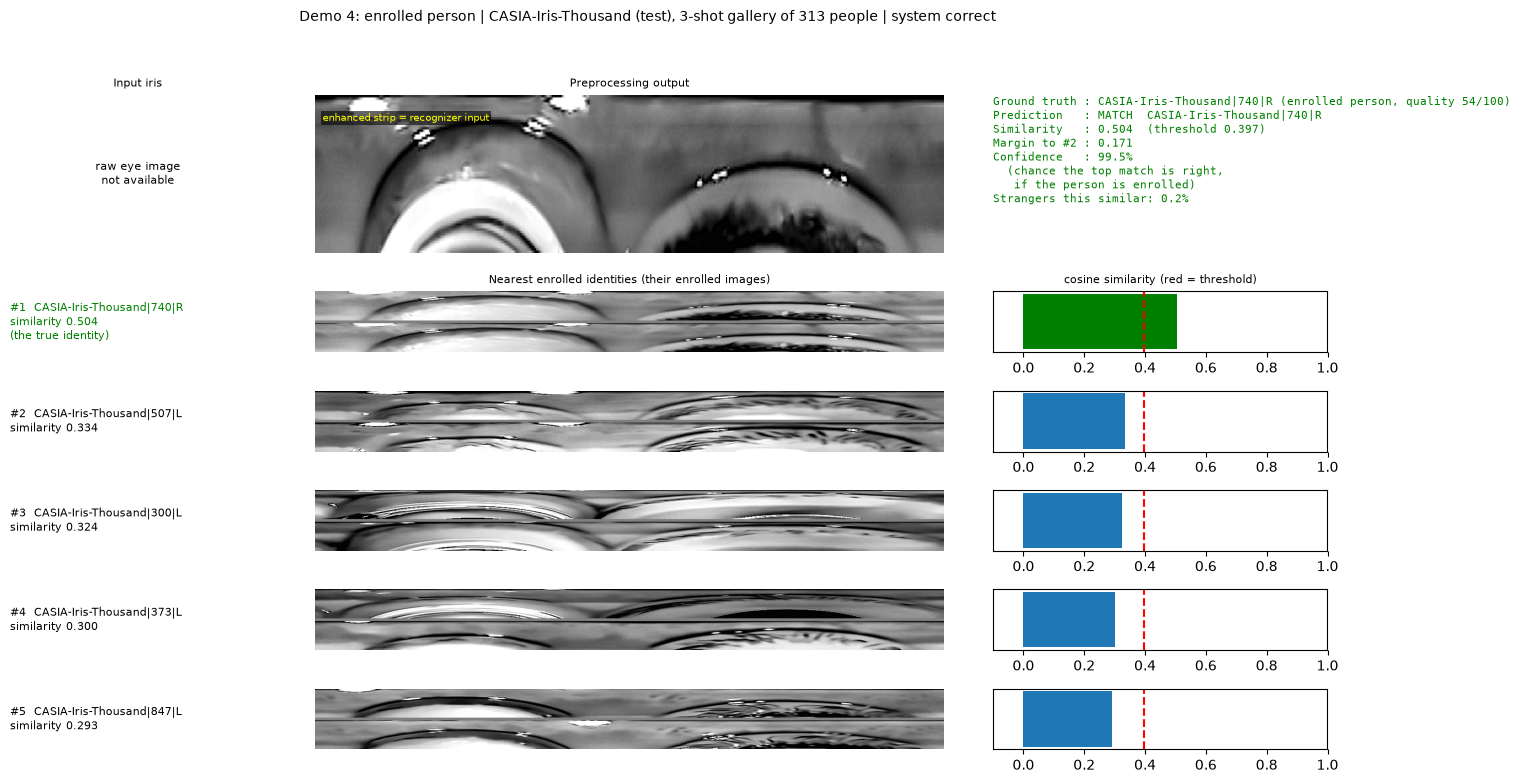

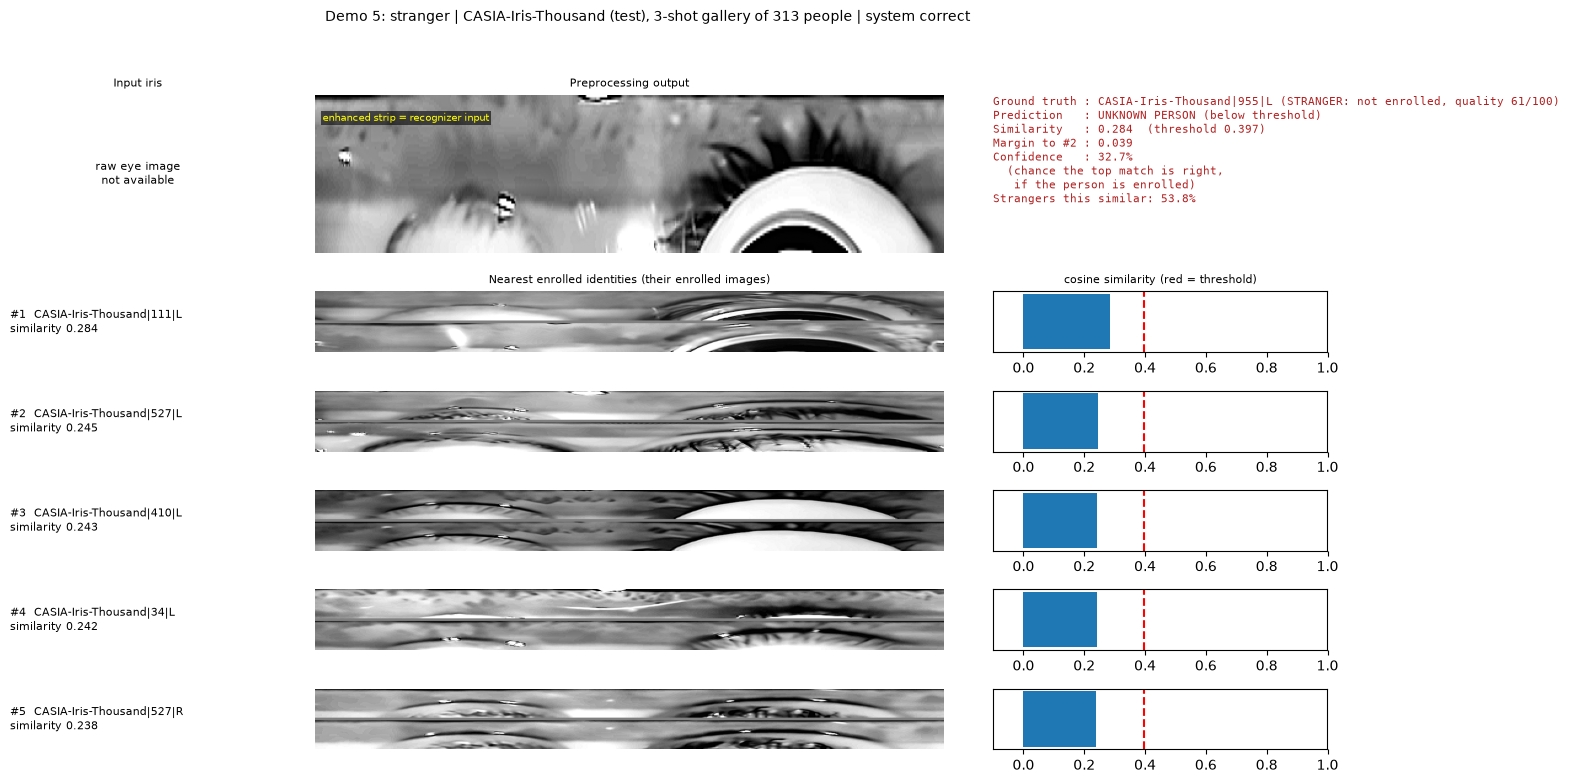

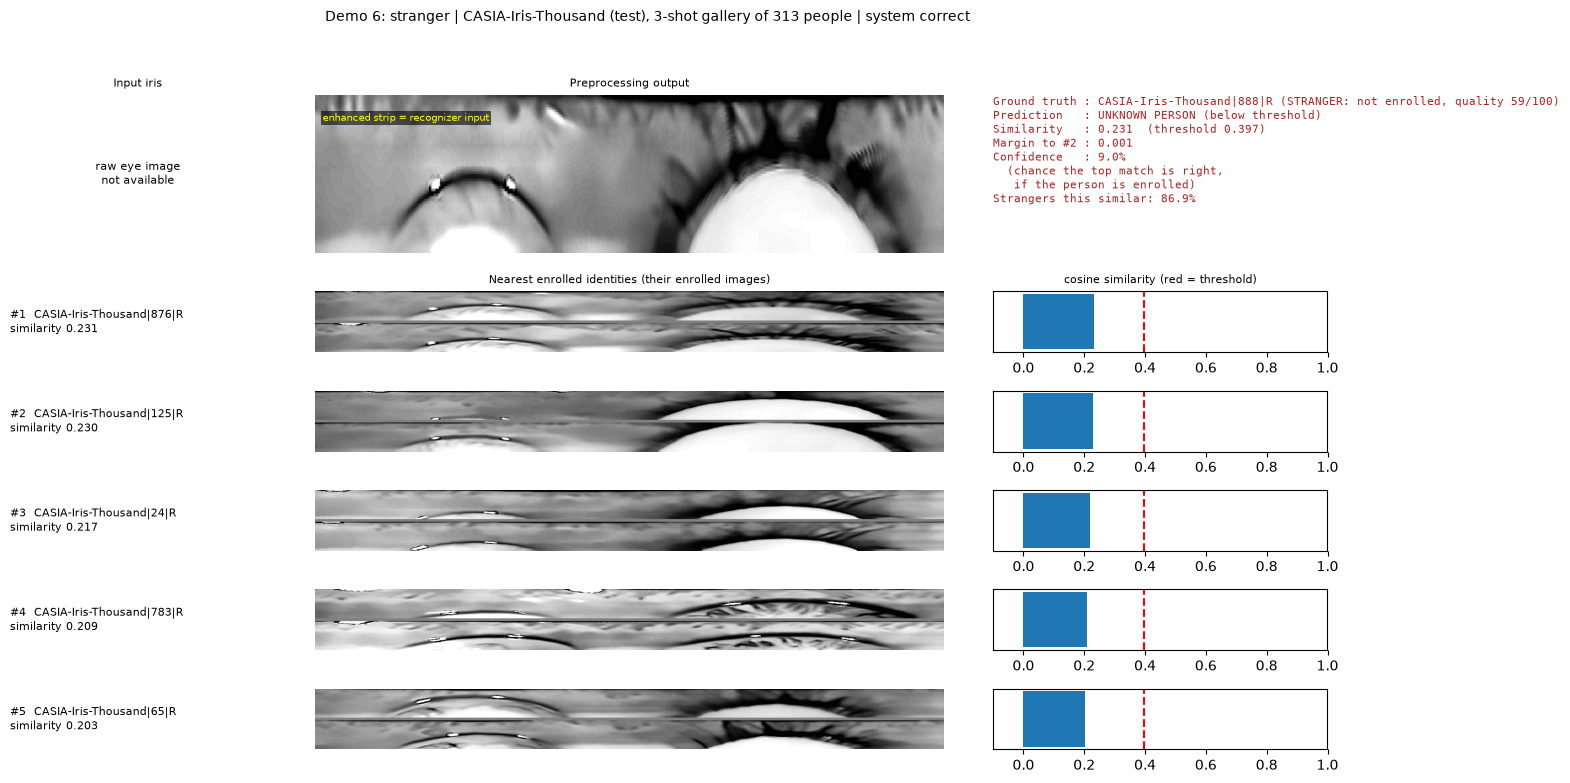

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\inference_demo\demo_predictions.csv | stored preprocessing outputs linked for 6 of 6 demo queries


,demo,kind,true_identity,predicted,system_correct,top1_similarity,margin,confidence,open_far
0,1,enrolled,CASIA-Iris-Thousand|938|R,CASIA-Iris-Thousand|938|R,True,0.617,0.367,1.000,0.000
1,2,enrolled,CASIA-Iris-Thousand|695|L,NaN,False,0.255,0.006,0.130,0.740
2,3,enrolled,CASIA-Iris-Thousand|903|R,NaN,False,0.394,0.074,0.818,0.056
3,4,enrolled,CASIA-Iris-Thousand|740|R,CASIA-Iris-Thousand|740|R,True,0.504,0.171,0.995,0.002
4,5,stranger,CASIA-Iris-Thousand|955|L,NaN,True,0.284,0.039,0.327,0.538
5,6,stranger,CASIA-Iris-Thousand|888|R,NaN,True,0.231,0.001,0.090,0.869


In [11]:
# ============================================================
# 9b. Run the demo queries
# ============================================================

query_df, query_classes = system["query"], system["query"]["class_id"].to_numpy()
rng = np.random.default_rng(DEMO_SEED)


def draw_queries(classes, n):
    classes = sorted(classes)
    chosen = rng.choice(len(classes), size=min(n, len(classes)), replace=False)
    picks = []
    for c in (classes[i] for i in chosen):
        candidates = np.flatnonzero(query_classes == c)
        if len(candidates):
            picks.append(int(rng.choice(candidates)))
    return picks


enrolled_picks = draw_queries(system["enrolled"], N_ENROLLED_QUERIES)
stranger_picks = draw_queries(system["strangers"], N_STRANGER_QUERIES)
demo_queries = [(i, "enrolled") for i in enrolled_picks] + [(i, "stranger") for i in stranger_picks]

demo_predictions, linked = [], 0
for n, (i, kind) in enumerate(demo_queries, start=1):
    row = query_df.iloc[i]
    strip = system["query_images"][i].numpy()
    prediction, _ = predict_embeddings(system["emb_query"][i:i + 1], system, cal)
    prediction = prediction[0]
    raw, circles, strips, info = stage_context(row["source_path"], strip)
    linked += int(info is not None)

    truth = row["class_id"]
    quality_text = f", quality {float(info['quality_score']):.0f}/100" if info is not None and finite_float(info.get("quality_score")) is not None else ""
    note = (f"{truth} (enrolled person{quality_text})" if kind == "enrolled" else f"{truth} (STRANGER: not enrolled{quality_text})")
    correct = (kind == "enrolled" and prediction["predicted"] == truth) or (kind == "stranger" and prediction["predicted"] is None)
    show_pipeline(f"Demo {n}: {'enrolled person' if kind == 'enrolled' else 'stranger'} | {POOLS[DEMO_POOL][0]} ({DEMO_POOL}), {SHOT}-shot gallery of "
                  f"{len(system['enrolled'])} people | system {'correct' if correct else 'WRONG'}",
                  raw, circles, strips, prediction, truth if kind == "enrolled" else None, note, f"demo_query_{n:02d}_{kind}")

    demo_predictions.append({"demo": n, "kind": kind, "query_row": i, "true_identity": truth, "predicted": prediction["predicted"],
                             "accepted": prediction["accepted"], "system_correct": correct, "top1_similarity": prediction["top1"],
                             "margin": prediction["margin"], "confidence": prediction["confidence"], "open_far": prediction["open_far"],
                             **{f"match_{r + 1}": c for r, c in enumerate(prediction["classes"])},
                             **{f"similarity_{r + 1}": s for r, s in enumerate(prediction["sims"])}})

demo_table = pd.DataFrame(demo_predictions)
demo_table.to_csv(RESULTS_DIR / "demo_predictions.csv", index=False)
print("Saved:", RESULTS_DIR / "demo_predictions.csv", f"| stored preprocessing outputs linked for {linked} of {len(demo_queries)} demo queries")
display(demo_table[["demo", "kind", "true_identity", "predicted", "system_correct", "top1_similarity", "margin", "confidence", "open_far"]].round(3))

## 10. How the system behaves on the whole pool

A demonstration shows a few examples; this cell measures **every probe** of the demo pool against the gallery of enrolled people (strangers included as probes):

| Group | Measure | Meaning |
|---|---|---|
| Enrolled people's probes | `rank1`, `rank5` | The true identity is the best / among the five best matches (ignoring the threshold) |
| | `accepted_correct` | Accepted **and** the right identity |
| | `accepted_wrong` | Accepted but the wrong identity (the dangerous error) |
| | `false_reject` | Rejected although the person is enrolled |
| Strangers' probes | `stranger_false_accept` | Accepted although nobody in the gallery is this person (the target is `TARGET_OPEN_FAR`, but the gallery is larger than the calibration gallery, so more is expected) |
| Confidence | `ece_pool` | Calibration error of the confidence on the **enrolled** probes of this pool (held out: the fit used only validation people), with a reliability diagram below |

In [12]:
# ============================================================
# 10. Behaviour on the whole pool
# ============================================================

predictions_all, similarity_all = predict_embeddings(system["emb_query"], system, cal)
index_of = {c: i for i, c in enumerate(system["enrolled"])}
is_enrolled = np.array([c in index_of for c in query_classes])
own_all = np.array([index_of.get(c, -1) for c in query_classes])
accepted_all = np.array([p["accepted"] for p in predictions_all])
confidence_all = np.array([p["confidence"] for p in predictions_all])
top1_index = similarity_all.argmax(axis=1)

rows_e = np.flatnonzero(is_enrolled)
rank = 1 + (similarity_all[rows_e] > similarity_all[rows_e, own_all[rows_e]][:, None]).sum(axis=1)
correct_e = top1_index[rows_e] == own_all[rows_e]
ece_pool, reliability_pool = expected_calibration_error(confidence_all[rows_e], correct_e.astype(float), CALIBRATION_BINS)
stranger_rows = np.flatnonzero(~is_enrolled)

batch = {
    "pool": f"{POOLS[DEMO_POOL][0]} ({DEMO_POOL})", "shot": SHOT, "enrolled_identities": len(system["enrolled"]),
    "chance_rank1": 1.0 / len(system["enrolled"]), "enrolled_probes": len(rows_e), "stranger_probes": len(stranger_rows),
    "rank1": float(correct_e.mean()), "rank5": float((rank <= 5).mean()),
    "accepted_correct": float((accepted_all[rows_e] & correct_e).mean()),
    "accepted_wrong": float((accepted_all[rows_e] & ~correct_e).mean()),
    "false_reject": float((~accepted_all[rows_e]).mean()),
    "stranger_false_accept": float(accepted_all[stranger_rows].mean()) if len(stranger_rows) else float("nan"),
    "target_open_far": TARGET_OPEN_FAR, "threshold": cal["threshold"],
    "mean_confidence_enrolled": float(confidence_all[rows_e].mean()), "ece_pool": ece_pool, "ece_validation": cal["ece"],
}
batch["decision_accuracy"] = float((float((accepted_all[rows_e] & correct_e).sum()) + float((~accepted_all[stranger_rows]).sum())) / len(query_classes))

batch_table = pd.DataFrame([batch])
batch_table.to_csv(RESULTS_DIR / "batch_evaluation.csv", index=False)
with open(RESULTS_DIR / "demo_system.json", "w") as f:
    json.dump({"model": str(model_path), "shot": SHOT, "pool": batch["pool"], "target_open_far": TARGET_OPEN_FAR, "threshold": cal["threshold"],
               "confidence_weights": cal["w"].tolist(), "confidence_mu": cal["mu"].tolist(), "confidence_sd": cal["sd"].tolist(),
               "enrolled": len(system["enrolled"]), "strangers": len(system["strangers"]), "demo_seed": DEMO_SEED}, f, indent=2)
print("Saved:", RESULTS_DIR / "batch_evaluation.csv", "|", RESULTS_DIR / "demo_system.json")
display(batch_table.T.rename(columns={0: "value"}))

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\inference_demo\batch_evaluation.csv | E:\Research\LargeScale_Synthetic_Iris_Generation\results\inference_demo\demo_system.json


,value
pool,CASIA-Iris-Thousand (test)
shot,3
enrolled_identities,313
chance_rank1,0.003195
enrolled_probes,1380
stranger_probes,334
rank1,0.78913
rank5,0.868841
accepted_correct,0.657246
accepted_wrong,0.017391


## 10b. Calibration figures

1. **Reliability diagram**: the average confidence of each bin against the share of correct top-1 matches. The diagonal is perfect calibration. The validation curve is where the confidence was **fitted** (optimistic); the demo-pool curve is **held out**.
2. **Score distributions**: top similarity of correct and wrong matches and of strangers, with the decision threshold. The more the stranger and correct-match curves overlap, the harder open-set identification is.

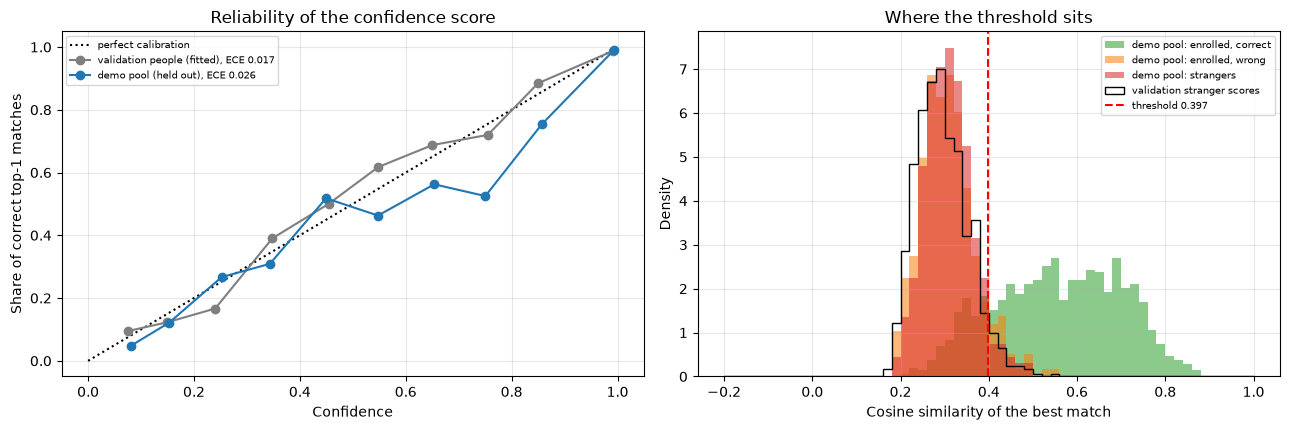

In [13]:
# ============================================================
# 10b. Calibration figures
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
ax.plot([0, 1], [0, 1], ":", color="black", label="perfect calibration")
for rows, label, color in [(cal["reliability"], f"validation people (fitted), ECE {cal['ece']:.3f}", "tab:gray"),
                           (reliability_pool, f"demo pool (held out), ECE {ece_pool:.3f}", "tab:blue")]:
    if rows:
        ax.plot([r[2] for r in rows], [r[3] for r in rows], marker="o", color=color, label=label)
ax.set_xlabel("Confidence")
ax.set_ylabel("Share of correct top-1 matches")
ax.set_title("Reliability of the confidence score")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)

ax = axes[1]
bins = np.linspace(-0.2, 1.0, 61)
top1_pool = np.array([p["top1"] for p in predictions_all])
ax.hist(top1_pool[rows_e][correct_e], bins=bins, alpha=0.55, density=True, color="tab:green", label="demo pool: enrolled, correct")
if (~correct_e).any():
    ax.hist(top1_pool[rows_e][~correct_e], bins=bins, alpha=0.55, density=True, color="tab:orange", label="demo pool: enrolled, wrong")
if len(stranger_rows):
    ax.hist(top1_pool[stranger_rows], bins=bins, alpha=0.55, density=True, color="tab:red", label="demo pool: strangers")
ax.hist(cal["stranger_scores"], bins=bins, histtype="step", density=True, color="black", label="validation stranger scores")
ax.axvline(cal["threshold"], color="red", linestyle="--", label=f"threshold {cal['threshold']:.3f}")
ax.set_xlabel("Cosine similarity of the best match")
ax.set_ylabel("Density")
ax.set_title("Where the threshold sits")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "calibration_and_scores.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
plt.close(fig)

## 11. Live preprocessing of a new eye image (optional)

For an image that is **not** in the dataset the preprocessing has to run live. The functions below are **my approximation written from the descriptions of Notebooks 02 to 04, not their code**:

| Function | Does |
|---|---|
| `segment_iris` | Pupil from a dark round blob, limbus from a Hough circle around it (falls back to 3 x the pupil radius) |
| `rubber_sheet` | Daugman normalization to 64 x 512, 3 o'clock origin |
| `enhance_strip` | Denoise, contrast stretch, CLAHE, sharpen |
| `ORIENTATION_VARIANTS` | The strip's radial and angular direction are not known from the descriptions, so four orientations are possible; section 11b picks the best by agreement with the stored strips |

The next cell tests the rubber sheet and the enhancement on a synthetic image (these assert), and tries the segmentation on a drawn eye (informative only, not an assert). **Section 11b measures how close the live strips are to the stored ones.**

In [14]:
# ============================================================
# 11. Live preprocessing functions and tests
# ============================================================

def segment_iris(gray):
    '''Approximate pupil / limbus detection (NOT the Notebook 02 code). Returns (pupil, limbus, note); circles are (cx, cy, r).'''
    h, w = gray.shape
    blur = cv2.GaussianBlur(gray, (9, 9), 2.0)
    binary = (blur <= float(np.percentile(blur, PUPIL_PERCENTILE))).astype(np.uint8)
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    count, labels, stats, centroids = cv2.connectedComponentsWithStats(binary)

    best, best_score = None, -1.0
    for i in range(1, count):
        area = float(stats[i, cv2.CC_STAT_AREA])
        if area < 150:
            continue
        distance = math.hypot(centroids[i][0] - w / 2.0, centroids[i][1] - h / 2.0)
        score = area / (1.0 + distance / (0.25 * min(h, w)))
        if score > best_score:
            best, best_score = i, score
    if best is None:
        return None, None, "no dark pupil-like region found"

    contours, _ = cv2.findContours((labels == best).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contour = max(contours, key=cv2.contourArea)
    (px, py), pr = cv2.minEnclosingCircle(contour)
    circularity = cv2.contourArea(contour) / (math.pi * pr * pr + 1e-9)
    if circularity < 0.55:
        return None, None, f"the dark region is not round (circularity {circularity:.2f})"
    pupil = (float(px), float(py), float(pr))

    circles = cv2.HoughCircles(cv2.medianBlur(gray, 5), cv2.HOUGH_GRADIENT, dp=1.0, minDist=max(h, w) / 4.0, param1=80, param2=28,
                               minRadius=max(int(round(1.6 * pr)), 10), maxRadius=int(round(min(h, w) / 2.0)))
    limbus, note = None, ""
    if circles is not None:
        candidates = [(float(x), float(y), float(r)) for x, y, r in circles[0]]
        candidates = [c for c in candidates if math.hypot(c[0] - px, c[1] - py) <= 0.5 * c[2] and c[2] > 1.4 * pr]
        if candidates:
            limbus = min(candidates, key=lambda c: math.hypot(c[0] - px, c[1] - py) + 0.1 * abs(c[2] - 3.0 * pr))
    if limbus is None:
        limbus, note = (pupil[0], pupil[1], 3.0 * pupil[2]), "no limbus circle found: a default radius of 3 x the pupil radius was used"
    return pupil, limbus, note


def rubber_sheet(gray, pupil, limbus, height=INPUT_HW[0], width=INPUT_HW[1]):
    '''Daugman rubber sheet: row 0 = pupil boundary, last row = limbus, column 0 = 3 o'clock.'''
    theta = np.linspace(0.0, 2.0 * np.pi, width, endpoint=False)
    r = np.linspace(0.0, 1.0, height)[:, None]
    xp, yp = pupil[0] + pupil[2] * np.cos(theta), pupil[1] + pupil[2] * np.sin(theta)
    xl, yl = limbus[0] + limbus[2] * np.cos(theta), limbus[1] + limbus[2] * np.sin(theta)
    map_x = ((1.0 - r) * xp[None, :] + r * xl[None, :]).astype(np.float32)
    map_y = ((1.0 - r) * yp[None, :] + r * yl[None, :]).astype(np.float32)
    return cv2.remap(gray, map_x, map_y, interpolation=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)


def enhance_strip(strip):
    '''Denoise, contrast stretch, CLAHE, sharpen (an approximation of Notebook 04).'''
    x = cv2.fastNlMeansDenoising(strip, None, 5, 7, 21)
    low, high = np.percentile(x, [1, 99])
    x = np.clip((x.astype(np.float32) - low) * (255.0 / max(float(high - low), 1.0)), 0, 255).astype(np.uint8)
    x = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(x)
    return cv2.addWeighted(x, 1.5, cv2.GaussianBlur(x, (0, 0), 1.5), -0.5, 0)


ORIENTATION_VARIANTS = {
    "as computed": lambda s: np.ascontiguousarray(s),
    "rows flipped": lambda s: np.ascontiguousarray(s[::-1]),
    "angle direction flipped": lambda s: np.ascontiguousarray(np.roll(s[:, ::-1], 1, axis=1)),
    "both flipped": lambda s: np.ascontiguousarray(np.roll(s[::-1, ::-1], 1, axis=1)),
}


def correlation(a, b):
    a, b = a.astype(np.float64).ravel(), b.astype(np.float64).ravel()
    a, b = a - a.mean(), b - b.mean()
    denominator = math.sqrt(float(np.sum(a * a)) * float(np.sum(b * b)))
    return float(np.sum(a * b) / denominator) if denominator > 0 else float("nan")


def embed_strips(net, strips):
    return extract_embeddings(net, torch.from_numpy(np.stack([np.ascontiguousarray(s) for s in strips])))


# ---- tests (asserted): rubber sheet on concentric rings, orientation variants, enhancement ----
yy, xx = np.mgrid[0:200, 0:200]
rings = np.clip(2.0 * np.hypot(xx - 100.0, yy - 100.0), 0, 255).astype(np.uint8)       # value = 2 x distance from the centre
strip_t = rubber_sheet(rings, (100.0, 100.0, 20.0), (100.0, 100.0, 80.0))
expected_rows = 2.0 * (20.0 + 60.0 * np.arange(INPUT_HW[0]) / (INPUT_HW[0] - 1))
assert strip_t.shape == INPUT_HW and strip_t.dtype == np.uint8
assert float(np.abs(strip_t.astype(float) - expected_rows[:, None]).max()) < 3.0, "the rubber sheet must map radius to rows"
assert bool(np.all(np.diff(strip_t[:, 0].astype(int)) >= -1)), "value must grow from the pupil to the limbus"

demo_strip = np.random.default_rng(0).integers(0, 256, INPUT_HW, dtype=np.uint8)
for name, function in ORIENTATION_VARIANTS.items():
    assert np.array_equal(function(function(demo_strip)), demo_strip), f"'{name}' must be its own inverse"
assert np.array_equal(ORIENTATION_VARIANTS["angle direction flipped"](demo_strip)[:, 0], demo_strip[:, 0]), "the 3 o'clock column must stay in place"
assert abs(correlation(demo_strip, demo_strip) - 1.0) < 1e-12 and abs(correlation(demo_strip, 255 - demo_strip) + 1.0) < 1e-9

enhanced_t = enhance_strip(strip_t)
assert enhanced_t.shape == INPUT_HW and enhanced_t.dtype == np.uint8 and float(enhanced_t.std()) > 0

# ---- informative only: segmentation of a drawn eye ----
eye = np.full((280, 320), 200, dtype=np.uint8)
cv2.circle(eye, (160, 140), 90, 110, -1)
cv2.circle(eye, (160, 140), 30, 15, -1)
eye = cv2.GaussianBlur(eye, (5, 5), 1.0)
pupil_s, limbus_s, note_s = segment_iris(eye)
if pupil_s is not None:
    print(f"Drawn eye (true pupil (160, 140, 30), limbus (160, 140, 90)): pupil {tuple(round(v, 1) for v in pupil_s)}, "
          f"limbus {tuple(round(v, 1) for v in limbus_s)} {note_s}")
else:
    print("Drawn eye: segmentation found no pupil:", note_s)

print("Live-preprocessing self-tests passed (rubber sheet, orientation variants, enhancement).")

Drawn eye (true pupil (160, 140, 30), limbus (160, 140, 90)): pupil (160.0, 140.0, 85.0), limbus (160.0, 140.0, 255.0) no limbus circle found: a default radius of 3 x the pupil radius was used
Live-preprocessing self-tests passed (rubber sheet, orientation variants, enhancement).


## 11b. How close is the live preprocessing to the stored one? And a new image

**Validation** (`VALIDATE_LIVE_PREPROCESSING`): for up to `LIVE_VALIDATION_IMAGES` demo-pool probes whose raw image and circles can be found, the notebook

1. builds a live strip from the **stored circles** (tests the rubber sheet and the enhancement) in all four orientations, and keeps the orientation with the best correlation to the stored enhanced strip;
2. builds a live strip from **its own segmentation** (tests everything) and measures the center and radius errors against the stored circles;
3. reports the **embedding cosine** between each live strip and the stored strip. A mean of at least `LIVE_MIN_EMBEDDING_COSINE` means the live path is close enough to use; otherwise treat live results as indicative only.

**A new image** (`RAW_IMAGE_PATH`): runs the whole pipeline live and draws the same figure (no ground truth). If the validation was skipped, orientation "as computed" is used.

In [15]:
# ============================================================
# 11b. Validate the live preprocessing; run a new image
# ============================================================

LIVE_VARIANT = "as computed"
live_table = pd.DataFrame()
live_verdict = None


def usable_stage_rows(limit=400):
    found = []
    for i, source in enumerate(query_df["source_path"]):
        info = stage_row(source)
        if info is None:
            continue
        original = info.get("original_path")
        values = [finite_float(info.get(k)) for k in STAGE_CIRCLE_KEYS]
        if isinstance(original, str) and Path(original).exists() and all(v is not None for v in values):
            found.append((i, original, values))
        if len(found) >= limit:
            break
    return found


if VALIDATE_LIVE_PREPROCESSING:
    candidates = usable_stage_rows()
    if not candidates:
        print("No demo-pool image could be linked to its raw image and circles; the live preprocessing is not validated.")
    else:
        pick = [candidates[j] for j in np.unique(np.linspace(0, len(candidates) - 1, min(LIVE_VALIDATION_IMAGES, len(candidates))).round().astype(int))]
        grays = [cv2.imread(path, cv2.IMREAD_GRAYSCALE) for _, path, _ in pick]
        stored = [system["query_images"][i].numpy() for i, _, _ in pick]
        raw_strips = [rubber_sheet(g, tuple(v[:3]), tuple(v[3:])) for g, (_, _, v) in zip(grays, pick)]
        enhanced = [enhance_strip(s) for s in raw_strips]

        scores = {name: float(np.nanmean([correlation(fn(e), st) for e, st in zip(enhanced, stored)])) for name, fn in ORIENTATION_VARIANTS.items()}
        LIVE_VARIANT = max(scores, key=scores.get)
        variant = ORIENTATION_VARIANTS[LIVE_VARIANT]
        print("Correlation with the stored strips by orientation:", {k: round(v, 3) for k, v in scores.items()}, "-> using:", LIVE_VARIANT)

        stored_embeddings = embed_strips(model, stored)
        circles_embeddings = embed_strips(model, [variant(e) for e in enhanced])
        rows = []
        own_strips, own_index = [], []
        for n, (g, (i, path, v)) in enumerate(zip(grays, pick)):
            pupil, limbus, note = segment_iris(g)
            row = {"query_row": i, "corr_stored_circles": correlation(variant(enhanced[n]), stored[n]),
                   "cos_stored_circles": float(np.sum(circles_embeddings[n] * stored_embeddings[n])), "segmentation_ok": pupil is not None,
                   "center_error_px": float("nan"), "pupil_radius_error_px": float("nan"), "limbus_radius_error_px": float("nan"),
                   "corr_own_segmentation": float("nan"), "cos_own_segmentation": float("nan"), "note": note}
            if pupil is not None:
                row.update(center_error_px=math.hypot(pupil[0] - v[0], pupil[1] - v[1]), pupil_radius_error_px=abs(pupil[2] - v[2]),
                           limbus_radius_error_px=abs(limbus[2] - v[5]))
                strip = variant(enhance_strip(rubber_sheet(g, pupil, limbus)))
                row["corr_own_segmentation"] = correlation(strip, stored[n])
                own_strips.append(strip)
                own_index.append(n)
            rows.append(row)
        if own_strips:
            own_embeddings = embed_strips(model, own_strips)
            for k, n in enumerate(own_index):
                rows[n]["cos_own_segmentation"] = float(np.sum(own_embeddings[k] * stored_embeddings[n]))

        live_table = pd.DataFrame(rows)
        live_table.to_csv(RESULTS_DIR / "live_preprocessing_validation.csv", index=False)
        mean_stored, mean_own = float(live_table["cos_stored_circles"].mean()), float(np.nanmean(live_table["cos_own_segmentation"])) if own_strips else float("nan")
        live_verdict = bool(mean_stored >= LIVE_MIN_EMBEDDING_COSINE and (not own_strips or mean_own >= LIVE_MIN_EMBEDDING_COSINE))
        print(f"\nEmbedding cosine live vs. stored: with the stored circles {mean_stored:.3f}, with my own segmentation {mean_own:.3f} "
              f"(segmentation found a pupil in {int(live_table['segmentation_ok'].sum())} of {len(live_table)} images)")
        print("Verdict:", "the live path is close to the stored pipeline" if live_verdict else
              f"NOT close enough (below {LIVE_MIN_EMBEDDING_COSINE}): treat live results as indicative only, or paste the Notebook 02-04 functions")
        display(live_table.describe().T[["mean", "min", "max"]].round(3))

if RAW_IMAGE_PATH is not None:
    gray = cv2.imread(str(RAW_IMAGE_PATH), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(f"Cannot read RAW_IMAGE_PATH: {RAW_IMAGE_PATH}")
    pupil, limbus, note = segment_iris(gray)
    if pupil is None:
        print("Live segmentation failed:", note)
    else:
        if note:
            print("Note:", note)
        variant = ORIENTATION_VARIANTS[LIVE_VARIANT]
        normalized = rubber_sheet(gray, pupil, limbus)
        strip = variant(enhance_strip(normalized))
        embedding = embed_strips(model, [strip])
        prediction = predict_embeddings(embedding, system, cal)[0][0]
        show_pipeline(f"Live path for {Path(RAW_IMAGE_PATH).name} (approximate preprocessing, orientation: {LIVE_VARIANT})", gray,
                      [(*pupil, "cyan"), (*limbus, "lime")], [("normalized strip (live)", variant(normalized)), ("enhanced strip = recognizer input (live)", strip)],
                      prediction, None, "unknown (new image)", "live_new_image")
else:
    print("RAW_IMAGE_PATH is not set: no new image was run (set it in Cell 6 to try your own eye image).")

No demo-pool image could be linked to its raw image and circles; the live preprocessing is not validated.
RAW_IMAGE_PATH is not set: no new image was run (set it in Cell 6 to try your own eye image).


## 11c. Completing the system: enrol, identify, save, batch, interact

The cells so far showed **identification** on a fixed gallery. A complete system also needs to:

| Capability | Function |
|---|---|
| **Enrol** a new person from a few images (enhanced strips, or raw eye images through the live preprocessing) | `enroll_from_strips`, `enroll_from_raw` |
| **Identify** one new raw eye image end to end | `identify_raw` |
| **Save and reload** the gallery with its threshold and confidence calibration | `save_gallery`, `load_gallery` |
| **Identify a folder** of images into a CSV | `identify_folder` |
| **Pick queries interactively** | `interactive_demo` |

The new functions never change the original `system`: enrolling returns an updated **copy**. Enrolling does **not** recalibrate: the threshold and the confidence still come from the validation people, so they become approximate as the gallery grows (sections 1.3 and 1.4). Raw-image functions use the **live approximation** of section 11, not the Notebook 02 to 04 code.

In [16]:
# ============================================================
# 11c. Configuration and functions of the extensions
# ============================================================

N_ENROLL_DEMO = 3                           # strangers enrolled in the enrolment demo
GALLERY_PATH = RESULTS_DIR / "gallery.npz"  # the saved gallery
FOLDER_FOR_BATCH_INFERENCE = None           # e.g. PROJECT_ROOT / "my_eyes": a folder of images to identify
FOLDER_KIND = "raw"                         # "raw" eye images (live preprocessing) or "strip" (enhanced 64 x 512 strips)
FOLDER_PATTERN = "*.png"
INTERACTIVE_QUERIES = 60                    # probes offered in the interactive demo
assert FOLDER_KIND in {"raw", "strip"} and N_ENROLL_DEMO >= 1 and INTERACTIVE_QUERIES >= 1


def show_with(sys_, cal_, *args, **kwargs):
    '''Draw show_pipeline for another gallery / calibration (show_pipeline reads the globals `system` and `cal`).'''
    global system, cal
    saved = (system, cal)
    system, cal = sys_, cal_
    try:
        show_pipeline(*args, **kwargs)
    finally:
        system, cal = saved


def enroll_from_strips(sys_, name, strips_uint8):
    '''Add a person from enhanced strips (uint8 [K, 64, 512]). Returns an updated COPY; sys_ is not changed.'''
    strips = np.stack([np.ascontiguousarray(s) for s in strips_uint8])
    assert strips.ndim == 3 and strips.shape[1:] == tuple(INPUT_HW) and strips.dtype == np.uint8, f"strips must be uint8 [K, {INPUT_HW[0]}, {INPUT_HW[1]}]"
    assert name not in set(sys_["enrolled"]), f"'{name}' is already enrolled"

    embeddings = extract_embeddings(model, torch.from_numpy(strips)).astype(np.float64)
    prototype = embeddings.sum(axis=0)
    prototype = prototype / max(float(np.linalg.norm(prototype)), 1e-12)

    updated = dict(sys_)
    start = len(sys_["support_images"])
    updated["enrolled"] = list(sys_["enrolled"]) + [name]
    updated["prototypes"] = np.concatenate([sys_["prototypes"], prototype[None, :]], axis=0)
    updated["support_images"] = torch.cat([sys_["support_images"], torch.from_numpy(strips)])
    updated["support_index"] = {**sys_["support_index"], name: list(range(start, start + len(strips)))}
    updated["strangers"] = set(sys_.get("strangers", set())) - {name}
    return updated


def preprocess_live(gray):
    '''Raw eye image -> circles, normalized strip, and enhanced strip (the recognizer input); {"ok": False} if segmentation fails.'''
    pupil, limbus, note = segment_iris(gray)
    if pupil is None:
        return {"ok": False, "note": note}
    variant = ORIENTATION_VARIANTS[LIVE_VARIANT]
    normalized = rubber_sheet(gray, pupil, limbus)
    return {"ok": True, "note": note, "pupil": pupil, "limbus": limbus,
            "normalized": variant(normalized), "strip": variant(enhance_strip(normalized))}


def enroll_from_raw(sys_, name, paths):
    '''Enrol a person from raw eye images through the live preprocessing (approximate, see section 11).'''
    strips = []
    for path in paths:
        gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if gray is None:
            raise FileNotFoundError(f"Cannot read {path}")
        result = preprocess_live(gray)
        if not result["ok"]:
            raise RuntimeError(f"Segmentation failed for {path}: {result['note']}")
        strips.append(result["strip"])
    return enroll_from_strips(sys_, name, np.stack(strips))


def identify_raw(path, sys_=None, cal_=None, show=True, name="identify_raw"):
    '''The whole pipeline for one raw eye image: segmentation, normalization, enhancement, recognition, prediction, confidence, nearest matches.'''
    sys_, cal_ = system if sys_ is None else sys_, cal if cal_ is None else cal_
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(f"Cannot read {path}")
    live = preprocess_live(gray)
    if not live["ok"]:
        print("Live segmentation failed:", live["note"])
        return None
    prediction = predict_embeddings(embed_strips(model, [live["strip"]]), sys_, cal_)[0][0]
    if show:
        show_with(sys_, cal_, f"Live pipeline for {Path(path).name} (approximate preprocessing, orientation: {LIVE_VARIANT})", gray,
                  [(*live["pupil"], "cyan"), (*live["limbus"], "lime")],
                  [("normalized strip (live)", live["normalized"]), ("enhanced strip = recognizer input (live)", live["strip"])],
                  prediction, None, "unknown (new image)", name)
    return prediction


def save_gallery(sys_, cal_, path):
    '''Save the gallery (identities, prototypes, enrolled strips) with the threshold and the confidence calibration.'''
    owners, strips = [], []
    for c in sys_["enrolled"]:
        index = sys_["support_index"][c]
        strips.append(sys_["support_images"][index].numpy())
        owners += [c] * len(index)
    np.savez_compressed(path, enrolled=np.array(sys_["enrolled"]), prototypes=sys_["prototypes"].astype(np.float32),
                        strips=np.concatenate(strips), strip_owner=np.array(owners), threshold=np.float64(cal_["threshold"]),
                        mu=cal_["mu"], sd=cal_["sd"], w=cal_["w"], stranger_sorted=cal_["stranger_sorted"],
                        shot=np.int64(SHOT), model=str(model_path), target_open_far=np.float64(TARGET_OPEN_FAR))
    return Path(path)


def load_gallery(path):
    '''(system, cal) restored from a file written by save_gallery. The system holds the gallery only (no probe images).'''
    data = np.load(path, allow_pickle=False)
    enrolled = [str(c) for c in data["enrolled"]]
    owners = np.array([str(c) for c in data["strip_owner"]])
    prototypes = data["prototypes"].astype(np.float64)
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)
    restored = {"enrolled": enrolled, "prototypes": prototypes, "support_images": torch.from_numpy(data["strips"]), "strangers": set(),
                "support_index": {c: np.flatnonzero(owners == c).tolist() for c in enrolled}}
    restored_cal = {"threshold": float(data["threshold"]), "mu": data["mu"], "sd": data["sd"], "w": data["w"],
                    "stranger_sorted": data["stranger_sorted"]}
    return restored, restored_cal


def identify_folder(folder, kind="raw", pattern="*.png", sys_=None, cal_=None):
    '''Identify every image of a folder. kind "raw": eye images through the live preprocessing; "strip": enhanced 64 x 512 strips.'''
    assert kind in {"raw", "strip"}
    sys_, cal_ = system if sys_ is None else sys_, cal if cal_ is None else cal_
    rows, strips, valid = [], [], []

    for path in sorted(Path(folder).glob(pattern)):
        gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if gray is None:
            rows.append({"file": path.name, "status": "unreadable"})
            continue
        if kind == "raw":
            live = preprocess_live(gray)
            if not live["ok"]:
                rows.append({"file": path.name, "status": "segmentation failed: " + live["note"]})
                continue
            strip = live["strip"]
        else:
            if gray.shape != tuple(INPUT_HW):
                rows.append({"file": path.name, "status": f"not a {INPUT_HW[0]}x{INPUT_HW[1]} strip"})
                continue
            strip = gray
        valid.append(len(rows))
        strips.append(strip)
        rows.append({"file": path.name, "status": "ok"})

    if strips:
        predictions, _ = predict_embeddings(embed_strips(model, strips), sys_, cal_)
        for row_index, p in zip(valid, predictions):
            rows[row_index].update({"decision": "match" if p["accepted"] else "unknown person", "predicted": p["predicted"],
                                    "top1_similarity": p["top1"], "margin": p["margin"], "confidence": p["confidence"],
                                    "stranger_rate_at_this_similarity": p["open_far"],
                                    **{f"match_{r + 1}": c for r, c in enumerate(p["classes"])},
                                    **{f"similarity_{r + 1}": s for r, s in enumerate(p["sims"])}})
    return pd.DataFrame(rows)


def demo_one(i, name="interactive_last"):
    '''The whole pipeline figure for probe i of the demo pool.'''
    row = query_df.iloc[i]
    strip = system["query_images"][i].numpy()
    kind = "enrolled" if row["class_id"] in set(system["enrolled"]) else "stranger"
    prediction = predict_embeddings(system["emb_query"][i:i + 1], system, cal)[0][0]
    raw, circles, strips, info = stage_context(row["source_path"], strip)
    truth = row["class_id"]
    note = f"{truth} (enrolled person)" if kind == "enrolled" else f"{truth} (STRANGER: not enrolled)"
    show_pipeline(f"Probe {i}: {kind}", raw, circles, strips, prediction, truth if kind == "enrolled" else None, note, name)
    return prediction


def interactive_demo(max_queries=INTERACTIVE_QUERIES):
    '''A dropdown of probes and a button that draws the pipeline for the chosen one (needs ipywidgets).'''
    try:
        import ipywidgets as widgets
        from IPython.display import clear_output
    except ImportError:
        print("ipywidgets is not installed (`pip install ipywidgets`); call demo_one(i) with a probe index i instead.")
        return None

    enrolled_set = set(system["enrolled"])
    picks = np.unique(np.linspace(0, len(query_df) - 1, min(max_queries, len(query_df))).round().astype(int))
    options = [(f"{i}: {query_classes[i]} ({'enrolled' if query_classes[i] in enrolled_set else 'stranger'})", int(i)) for i in picks]
    dropdown = widgets.Dropdown(options=options, description="Probe:", layout=widgets.Layout(width="520px"))
    button = widgets.Button(description="Identify", button_style="primary")
    out = widgets.Output()

    def on_click(_):
        with out:
            clear_output(wait=True)
            demo_one(dropdown.value)

    button.on_click(on_click)
    display(widgets.HBox([dropdown, button]), out)
    return dropdown


import importlib.util
INTERACTIVE_AVAILABLE = importlib.util.find_spec("ipywidgets") is not None
print("Extension functions defined. Interactive widgets available:", INTERACTIVE_AVAILABLE)

Extension functions defined. Interactive widgets available: True


Enrolment tests passed.
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\inference_demo\enrollment_demo.csv (before enrolment every acceptance is wrong: the person is not in the gallery)


,person,probes,before_rejected_as_unknown,before_accepted_as_someone_else,after_identified_correctly,after_rejected,gallery_before,gallery_after
0,CASIA-Iris-Thousand|108|L,5,1.0,0.0,0.6,0.4,313,314
1,CASIA-Iris-Thousand|139|L,5,1.0,0.0,0.8,0.2,313,314
2,CASIA-Iris-Thousand|150|L,5,1.0,0.0,0.4,0.6,313,314


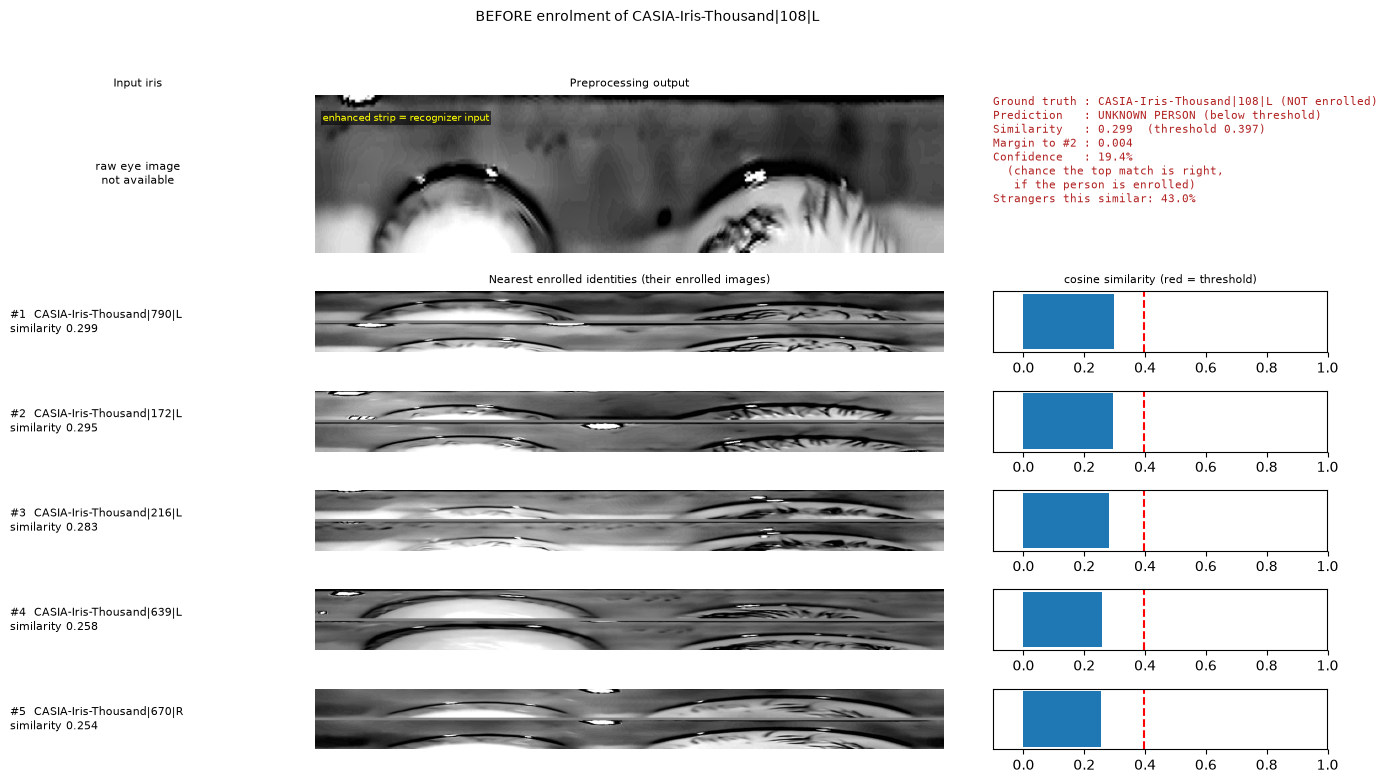

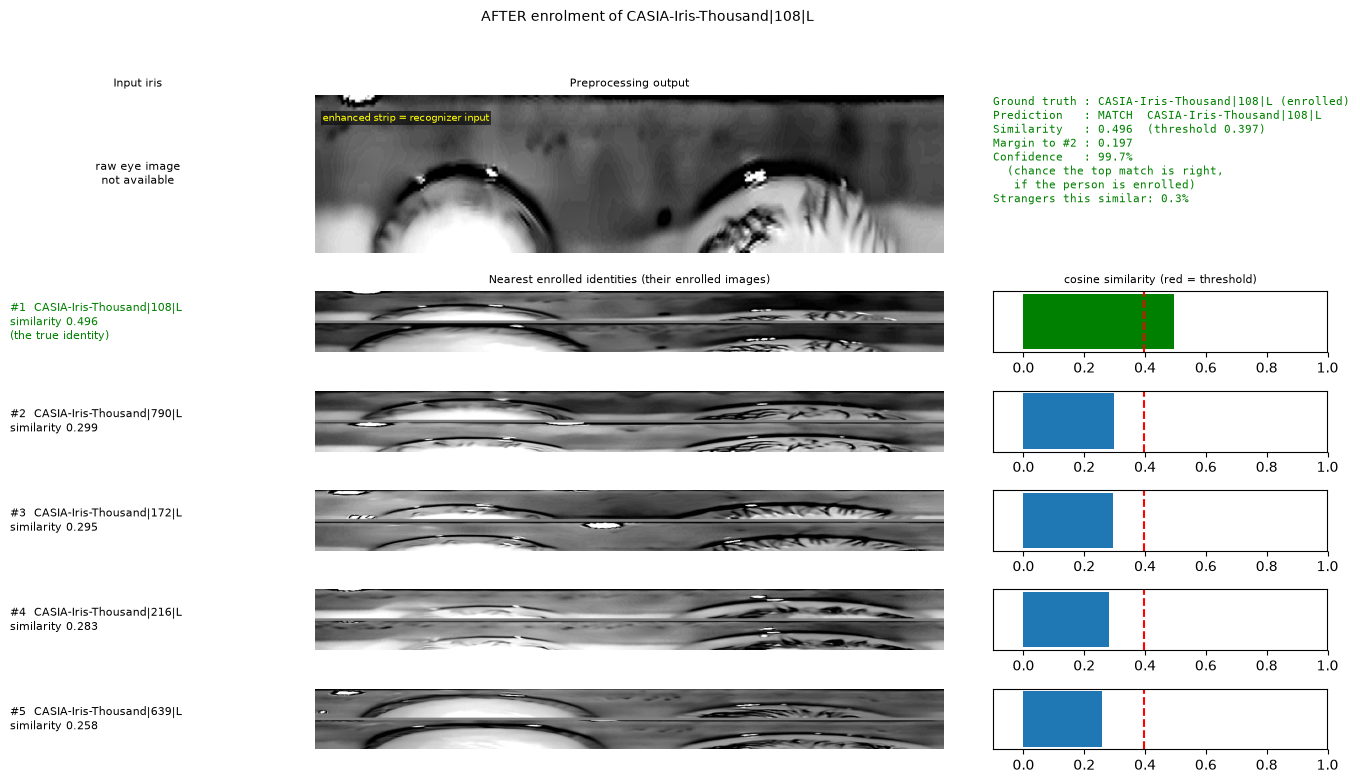

In [17]:
# ============================================================
# 11d. Enrolment: tests and the open-set -> enrolled demonstration
# ============================================================

ENROL_TESTS_PASSED = False
n_before = len(system["enrolled"])
stranger_list = sorted(system["strangers"])
assert stranger_list, "there is no stranger in the demo pool to enrol"
test_name = stranger_list[0]
test_strips = system["support_images"][system["support_index"][test_name]].numpy()
enrolled_system = enroll_from_strips(system, test_name, test_strips)

assert len(system["enrolled"]) == n_before and test_name not in set(system["enrolled"]), "enrolling must not change the original gallery"
assert len(enrolled_system["enrolled"]) == n_before + 1 and enrolled_system["prototypes"].shape[0] == n_before + 1
assert abs(float(np.linalg.norm(enrolled_system["prototypes"][-1])) - 1.0) < 1e-9, "the new prototype must have unit length"
assert np.allclose(enrolled_system["prototypes"][:n_before], system["prototypes"]), "the other prototypes must not change"
assert test_name in system["strangers"] and test_name not in enrolled_system["strangers"]
assert len(enrolled_system["support_index"][test_name]) == len(test_strips)

raised = False
try:
    enroll_from_strips(enrolled_system, test_name, test_strips)
except AssertionError:
    raised = True
assert raised, "enrolling the same name twice must raise"
ENROL_TESTS_PASSED = True
print("Enrolment tests passed.")

# ---- a stranger is rejected before enrolment and identified after it ----
enroll_rows = []
for c in stranger_list[:N_ENROLL_DEMO]:
    probes = np.flatnonzero(query_classes == c)
    if len(probes) == 0:
        continue
    updated = enroll_from_strips(system, c, system["support_images"][system["support_index"][c]].numpy())
    before = predict_embeddings(system["emb_query"][probes], system, cal)[0]
    after = predict_embeddings(system["emb_query"][probes], updated, cal)[0]
    enroll_rows.append({"person": c, "probes": len(probes),
                        "before_rejected_as_unknown": float(np.mean([not p["accepted"] for p in before])),
                        "before_accepted_as_someone_else": float(np.mean([p["accepted"] for p in before])),
                        "after_identified_correctly": float(np.mean([p["predicted"] == c for p in after])),
                        "after_rejected": float(np.mean([not p["accepted"] for p in after])),
                        "gallery_before": len(system["enrolled"]), "gallery_after": len(updated["enrolled"])})

enrollment_table = pd.DataFrame(enroll_rows)
enrollment_table.to_csv(RESULTS_DIR / "enrollment_demo.csv", index=False)
print("Saved:", RESULTS_DIR / "enrollment_demo.csv", "(before enrolment every acceptance is wrong: the person is not in the gallery)")
display(enrollment_table.round(3))

if enroll_rows:
    c = enroll_rows[0]["person"]
    i = int(np.flatnonzero(query_classes == c)[0])
    updated = enroll_from_strips(system, c, system["support_images"][system["support_index"][c]].numpy())
    raw, circles, strips, info = stage_context(query_df.iloc[i]["source_path"], system["query_images"][i].numpy())
    for label, gallery in (("BEFORE", system), ("AFTER", updated)):
        prediction = predict_embeddings(system["emb_query"][i:i + 1], gallery, cal)[0][0]
        show_with(gallery, cal, f"{label} enrolment of {c}", raw, circles, strips, prediction, c if label == "AFTER" else None,
                  f"{c} ({'enrolled' if label == 'AFTER' else 'NOT enrolled'})", f"enrollment_{label.lower()}")

In [18]:
# ============================================================
# 11e. Save and reload the gallery; identify a folder
# ============================================================

# ---- save and reload ----
saved_path = save_gallery(system, cal, GALLERY_PATH)
loaded_system, loaded_cal = load_gallery(saved_path)
rows_sample = np.arange(min(300, len(query_df)))
pred_a, sim_a = predict_embeddings(system["emb_query"][rows_sample], system, cal)
pred_b, sim_b = predict_embeddings(system["emb_query"][rows_sample], loaded_system, loaded_cal)

GALLERY_ROUNDTRIP = {
    "same_identities": loaded_system["enrolled"] == system["enrolled"],
    "max_sim_diff": float(np.max(np.abs(sim_a - sim_b))),
    "decision_flips": int(sum(a["accepted"] != b["accepted"] or a["classes"][0] != b["classes"][0] for a, b in zip(pred_a, pred_b))),
    "n": len(rows_sample), "threshold_equal": abs(loaded_cal["threshold"] - cal["threshold"]) < 1e-12,
    "strips_equal": all(len(loaded_system["support_index"][c]) == len(system["support_index"][c]) for c in system["enrolled"]),
    "size_mb": saved_path.stat().st_size / 1e6}
print(f"Saved gallery: {saved_path} ({GALLERY_ROUNDTRIP['size_mb']:.1f} MB) | after reloading: same identities {GALLERY_ROUNDTRIP['same_identities']}, "
      f"largest similarity difference {GALLERY_ROUNDTRIP['max_sim_diff']:.1e}, decisions flipped {GALLERY_ROUNDTRIP['decision_flips']} of {GALLERY_ROUNDTRIP['n']}")

# ---- folder inference: test on a few probe strips written as PNG files ----
test_dir = RESULTS_DIR / "folder_inference_test"
test_dir.mkdir(parents=True, exist_ok=True)
for stale in test_dir.glob("*.png"):
    stale.unlink()
test_rows = [int(i) for i in np.unique(np.linspace(0, len(query_df) - 1, min(10, len(query_df))).round().astype(int))]
for i in test_rows:
    cv2.imwrite(str(test_dir / f"probe_{i:06d}.png"), system["query_images"][i].numpy())

folder_table = identify_folder(test_dir, kind="strip", pattern="probe_*.png")
folder_table.to_csv(RESULTS_DIR / "folder_predictions_test.csv", index=False)

ok_rows = folder_table[folder_table["status"] == "ok"]
differences, mismatches = [], 0
for _, r in ok_rows.iterrows():
    i = int(r["file"].split("_")[1].split(".")[0])
    differences.append(abs(float(r["top1_similarity"]) - predictions_all[i]["top1"]))
    mismatches += int(r["match_1"] != predictions_all[i]["classes"][0])

FOLDER_TEST = {"n_files": len(test_rows), "n_ok": len(ok_rows), "max_sim_diff": max(differences) if differences else float("nan"), "top1_mismatch": mismatches}
print(f"Folder inference test: {FOLDER_TEST['n_ok']} of {FOLDER_TEST['n_files']} files identified, largest similarity difference to the batch "
      f"result {FOLDER_TEST['max_sim_diff']:.1e}, different best match: {FOLDER_TEST['top1_mismatch']}")
display(folder_table[["file", "status", "decision", "predicted", "top1_similarity", "confidence"]].round(3))

# ---- your own folder (optional) ----
if FOLDER_FOR_BATCH_INFERENCE is not None:
    user_table = identify_folder(FOLDER_FOR_BATCH_INFERENCE, kind=FOLDER_KIND, pattern=FOLDER_PATTERN)
    user_table.to_csv(RESULTS_DIR / "folder_predictions.csv", index=False)
    print(f"Identified {int((user_table['status'] == 'ok').sum())} of {len(user_table)} files in {FOLDER_FOR_BATCH_INFERENCE} "
          f"(kind: {FOLDER_KIND}). Saved: {RESULTS_DIR / 'folder_predictions.csv'}")
    display(user_table.head(20))
else:
    print("FOLDER_FOR_BATCH_INFERENCE is not set: no folder of your own was identified (set it in Cell 27b).")

Saved gallery: E:\Research\LargeScale_Synthetic_Iris_Generation\results\inference_demo\gallery.npz (22.7 MB) | after reloading: same identities True, largest similarity difference 7.4e-09, decisions flipped 0 of 300
Folder inference test: 10 of 10 files identified, largest similarity difference to the batch result 1.7e-04, different best match: 0


,file,status,decision,predicted,top1_similarity,confidence
0,probe_000000.png,ok,match,CASIA-Iris-Thousand|0|L,0.608,1.000
1,probe_000190.png,ok,unknown person,NaN,0.340,0.787
2,probe_000381.png,ok,unknown person,NaN,0.352,0.805
3,probe_000571.png,ok,match,CASIA-Iris-Thousand|473|L,0.586,1.000
4,probe_000761.png,ok,match,CASIA-Iris-Thousand|560|R,0.521,1.000
5,probe_000952.png,ok,unknown person,NaN,0.244,0.120
6,probe_001142.png,ok,unknown person,NaN,0.284,0.191
7,probe_001332.png,ok,match,CASIA-Iris-Thousand|7|R,0.481,0.998
8,probe_001523.png,ok,match,CASIA-Iris-Thousand|892|R,0.545,1.000
9,probe_001713.png,ok,match,CASIA-Iris-Thousand|998|R,0.408,0.989


FOLDER_FOR_BATCH_INFERENCE is not set: no folder of your own was identified (set it in Cell 27b).


In [19]:
# ============================================================
# 11f. Interactive demo (needs ipywidgets: pip install ipywidgets)
# ============================================================

interactive_demo()

Output()

Dropdown(description='Probe:', layout=Layout(width='520px'), options=(('0: CASIA-Iris-Thousand|0|L (enrolled)'…

## 12. Sanity checks

**Stop the notebook if:**
- the model was not trained on the source dataset only, or the demo pool contains a training identity (asserted earlier);
- fewer than two identities are enrolled, the threshold is not finite, or a confidence or open-set rate is outside `[0, 1]`;
- the ranked matches of a prediction are not in descending order, or its first match is not the maximum similarity;
- the batch Rank-1 differs from a brute-force recomputation;
- a results file is missing.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- the calibration used fewer than `MIN_CALIBRATION_QUERIES` probes, or the held-out calibration error is above 0.10;
- the closed-set Rank-1 is not above twice chance;
- the stranger false-accept rate is more than three times the target (a larger gallery than the calibration gallery, or a domain shift);
- a prediction made from a single image differs from the batch prediction;
- the stored preprocessing outputs could not be linked for most demo queries;
- the live preprocessing is not close to the stored one.

In [20]:
# ============================================================
# 12. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


add_check("the model never trained on an identity of the demo pool or the calibration people",
          not (trained_classes & (set(system["support"]["class_id"]) | set(system["query"]["class_id"]))))
add_check("at least two identities are enrolled", len(system["enrolled"]) >= 2, f"{len(system['enrolled'])} enrolled")
add_check("the decision threshold is finite", bool(np.isfinite(cal["threshold"])), f"{cal['threshold']:.3f}")

confidence_ok = bool(((confidence_all >= 0) & (confidence_all <= 1)).all())
open_far_all = np.array([p["open_far"] for p in predictions_all])
add_check("every confidence and open-set rate lies in [0, 1]", confidence_ok and bool(((open_far_all >= 0) & (open_far_all <= 1)).all()))

ordered_ok = all(all(a >= b - 1e-12 for a, b in zip(p["sims"], p["sims"][1:])) for p in predictions_all)
first_ok = all(abs(p["sims"][0] - p["top1"]) < 1e-9 for p in predictions_all)
add_check("the ranked matches are in descending order and the first is the maximum", ordered_ok and first_ok)

brute_rank1 = float(np.mean([int(np.argmax(similarity_all[q]) == own_all[q]) for q in rows_e]))
add_check("the batch Rank-1 equals a brute-force recomputation", abs(batch["rank1"] - brute_rank1) < 1e-12, f"{batch['rank1']:.4f}")

written = [n for n in ["demo_predictions.csv", "batch_evaluation.csv", "demo_system.json"] if not (RESULTS_DIR / n).exists()]
add_check("every results file was written", not written, f"missing: {written}")

# ---- warnings ----
add_check(f"at least {MIN_CALIBRATION_QUERIES} validation probes for the calibration", cal["n_queries"] >= MIN_CALIBRATION_QUERIES, f"{cal['n_queries']} probes", critical=False)
add_check("the held-out calibration error (ECE) is at most 0.10", batch["ece_pool"] <= 0.10, f"{batch['ece_pool']:.3f}", critical=False)
add_check("the closed-set Rank-1 is more than twice chance", batch["rank1"] > 2 * batch["chance_rank1"], f"{batch['rank1']:.3f} vs chance {batch['chance_rank1']:.4f}", critical=False)
if np.isfinite(batch["stranger_false_accept"]):
    add_check("the stranger false-accept rate is at most three times the target", batch["stranger_false_accept"] <= 3 * TARGET_OPEN_FAR,
              f"{batch['stranger_false_accept']:.3f} vs target {TARGET_OPEN_FAR}", critical=False)

mismatch = 0
for (i, kind), logged in zip(demo_queries, demo_predictions):
    single = embed_strips(model, [system["query_images"][i].numpy()])
    p_single = predict_embeddings(single, system, cal)[0][0]
    mismatch += int(p_single["classes"][0] != predictions_all[i]["classes"][0] or abs(p_single["top1"] - predictions_all[i]["top1"]) > 5e-3)
add_check("a single-image prediction equals the batch prediction (same best match, similarity within 0.005)", mismatch == 0, f"{mismatch} of {len(demo_queries)} differ", critical=False)

add_check("the stored preprocessing outputs were linked for most demo queries", linked >= max(1, len(demo_queries)) / 2 or not SHOW_STAGE_IMAGES,
          f"{linked} of {len(demo_queries)} linked", critical=False)
if live_verdict is not None:
    add_check("the live preprocessing is close to the stored one", live_verdict, f"see live_preprocessing_validation.csv (threshold {LIVE_MIN_EMBEDDING_COSINE})", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "demo_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "demo_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical demo checks failed: {failed_names}"
print("\nDemo sanity checks completed with no critical failures.")

[PASS] the model never trained on an identity of the demo pool or the calibration people
[PASS] at least two identities are enrolled  (313 enrolled)
[PASS] the decision threshold is finite  (0.397)
[PASS] every confidence and open-set rate lies in [0, 1]
[PASS] the ranked matches are in descending order and the first is the maximum
[PASS] the batch Rank-1 equals a brute-force recomputation  (0.7891)
[PASS] every results file was written  (missing: [])
[PASS] at least 50 validation probes for the calibration  (858 probes)
[PASS] the held-out calibration error (ECE) is at most 0.10  (0.026)
[PASS] the closed-set Rank-1 is more than twice chance  (0.789 vs chance 0.0032)
[PASS] the stranger false-accept rate is at most three times the target  (0.051 vs target 0.05)
[PASS] a single-image prediction equals the batch prediction (same best match, similarity within 0.005)  (0 of 6 differ)
[PASS] the stored preprocessing outputs were linked for most demo queries  (6 of 6 linked)

Saved: E:\Rese

In [21]:
# ============================================================
# 12b. Extra sanity checks for the extensions
# ============================================================

add_check("the enrolment functions work (original unchanged, unit-length prototype, duplicate names rejected)", ENROL_TESTS_PASSED)
add_check("the gallery survives saving and loading (same identities, similarities within 1e-5, same threshold)",
          GALLERY_ROUNDTRIP["same_identities"] and GALLERY_ROUNDTRIP["max_sim_diff"] < 1e-5
          and GALLERY_ROUNDTRIP["threshold_equal"] and GALLERY_ROUNDTRIP["strips_equal"],
          f"largest difference {GALLERY_ROUNDTRIP['max_sim_diff']:.1e}")
add_check("folder inference returned a result for every written file", FOLDER_TEST["n_ok"] == FOLDER_TEST["n_files"],
          f"{FOLDER_TEST['n_ok']} of {FOLDER_TEST['n_files']}")
add_check("folder inference matches the batch predictions (similarity within 0.005)", FOLDER_TEST["max_sim_diff"] < 5e-3,
          f"largest difference {FOLDER_TEST['max_sim_diff']:.1e}")

missing_files = [n for n in ["gallery.npz", "enrollment_demo.csv", "folder_predictions_test.csv"] if not (RESULTS_DIR / n).exists()]
add_check("every extension file was written", not missing_files, f"missing: {missing_files}")

# ---- warnings ----
add_check("saving and loading flips no decision", GALLERY_ROUNDTRIP["decision_flips"] == 0,
          f"{GALLERY_ROUNDTRIP['decision_flips']} of {GALLERY_ROUNDTRIP['n']} flipped", critical=False)
add_check("the best match of every folder prediction equals the batch prediction", FOLDER_TEST["top1_mismatch"] == 0,
          f"{FOLDER_TEST['top1_mismatch']} differ", critical=False)
if len(enrollment_table):
    share = float(enrollment_table["after_identified_correctly"].mean())
    add_check("after enrolment at least half of a person's probes are identified correctly", share >= 0.5, f"{share:.2f}", critical=False)
add_check("ipywidgets is available (interactive demo)", INTERACTIVE_AVAILABLE, "pip install ipywidgets", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "demo_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "demo_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical demo checks failed: {failed_names}"
print("\nAll demo sanity checks (including the extensions) completed with no critical failures.")

[PASS] the enrolment functions work (original unchanged, unit-length prototype, duplicate names rejected)
[PASS] the gallery survives saving and loading (same identities, similarities within 1e-5, same threshold)  (largest difference 7.4e-09)
[PASS] folder inference returned a result for every written file  (10 of 10)
[PASS] folder inference matches the batch predictions (similarity within 0.005)  (largest difference 1.7e-04)
[PASS] every extension file was written  (missing: [])
[PASS] saving and loading flips no decision  (0 of 300 flipped)
[PASS] the best match of every folder prediction equals the batch prediction  (0 differ)
[PASS] after enrolment at least half of a person's probes are identified correctly  (0.60)
[PASS] ipywidgets is available (interactive demo)  (pip install ipywidgets)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\inference_demo\demo_sanity_checks.csv

All demo sanity checks (including the extensions) completed with no critical failures.


## 12c. Final outputs of the extensions, and how to use them

New files in `results/inference_demo/`:

```text
gallery.npz                         the saved gallery with its threshold and confidence calibration (reload with load_gallery)
enrollment_demo.csv                 strangers rejected before and identified after enrolment
folder_predictions_test.csv         folder inference on probe strips (and folder_predictions.csv for your own folder)
figures/ enrollment_before.png, enrollment_after.png, interactive_last.png
```

### Using the complete system

```python
# enrol a new person from raw eye images (live preprocessing, approximate)
my_system = enroll_from_raw(system, "alice", ["alice_1.png", "alice_2.png", "alice_3.png"])

# identify a new raw eye image end to end (draws the whole pipeline)
prediction = identify_raw("probe.png", my_system, cal)

# save the gallery, and use it later without the demo pool
save_gallery(my_system, cal, "my_gallery.npz")
system2, cal2 = load_gallery("my_gallery.npz")
table = identify_folder("my_folder", kind="raw", sys_=system2, cal_=cal2)      # a CSV-ready table
```

### Remember

1. **Enrolling does not recalibrate.** The threshold and the confidence come from the validation people and the original gallery size; they become approximate as the gallery grows.
2. **Raw-image functions use my approximate preprocessing.** Check Cell 27's verdict before relying on them, or paste the exact Notebook 02 to 04 functions to replace `segment_iris`, `rubber_sheet`, and `enhance_strip`.
3. **A saved gallery needs the same model file.** `gallery.npz` stores the model path, not the weights; load it with the model it was built with.
4. The interactive demo and the folder inference are conveniences; the evidence remains the batch evaluation (Cell 21).

## 13. Final outputs

```text
results/inference_demo/
├── demo_predictions.csv            one row per demo query: ranked matches, similarities, decision, confidence
├── batch_evaluation.csv            how the system behaves on every probe of the pool
├── demo_system.json                model, threshold, and confidence calibration (to reproduce the demo)
├── live_preprocessing_validation.csv    live vs. stored preprocessing (if validated)
├── demo_sanity_checks.csv
└── figures/ demo_query_<n>_<kind>.png, calibration_and_scores.png, live_new_image.png
```

In [22]:
# ============================================================
# 13. Final output listing
# ============================================================

print("Notebook 19 output directory:")
print(RESULTS_DIR)
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")
print("figures/")
for path in sorted(FIG_DIR.iterdir()):
    print(f"- {path.name}")

print(f"\nModel: {model_path.name} | enrolled: {len(system['enrolled'])} | strangers: {len(system['strangers'])} | demo queries: {len(demo_queries)}")
print("\nNotebook 19 completed.")

Notebook 19 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\inference_demo
- batch_evaluation.csv
- demo_predictions.csv
- demo_sanity_checks.csv
- demo_system.json
- enrollment_demo.csv
- folder_predictions_test.csv
- gallery.npz
figures/
- calibration_and_scores.png
- demo_query_01_enrolled.png
- demo_query_02_enrolled.png
- demo_query_03_enrolled.png
- demo_query_04_enrolled.png
- demo_query_05_stranger.png
- demo_query_06_stranger.png
- enrollment_after.png
- enrollment_before.png

Model: best_3shot.pt | enrolled: 313 | strangers: 78 | demo queries: 6

Notebook 19 completed.


## 14. Using the system, and what to say about it

### Identify a strip in your own code

```python
embedding = embed_strips(model, [strip_uint8])                         # a 64 x 512 enhanced strip
prediction = predict_embeddings(embedding, system, cal)[0][0]          # ranked matches, similarity, margin, confidence, decision
```

### How to describe the demo honestly

1. **The unit of evidence is the batch evaluation**, not the pictures. Report `rank1`, `accepted_wrong`, `false_reject`, and `stranger_false_accept` with the **gallery size** and the **shot**.
2. **The confidence is calibrated on validation people** and measured on the demo pool; quote the held-out ECE, and say it depends on the gallery size and the dataset.
3. **The threshold rule** is "lets at most `TARGET_OPEN_FAR` of validation stranger scores through"; the real stranger false-accept rate is in the table.
4. **Preprocessing:** state which images used the **stored outputs of Notebooks 02 to 05** and which used the **live approximation** (and its validation verdict).
5. One model and one seed: this is a demonstration, not a significance test (Notebook 18).

### Reading the results

| What you see | Likely cause | What to try |
|---|---|---|
| High Rank-1 but many strangers accepted | The gallery is larger than the calibration gallery, or the threshold is lenient | Lower `TARGET_OPEN_FAR`; compare with the validation size |
| Many enrolled people rejected | The threshold is strict, or a domain shift (use `DEMO_POOL = "cross"`) | Raise `TARGET_OPEN_FAR`; look at the score distributions |
| Large held-out ECE | The confidence was fitted on different data (gallery size, dataset) | Report it; do not present the confidence as a probability for this pool |
| Live strips differ from stored ones | The approximate preprocessing is not the Notebook 02 to 04 code | Use stored outputs, or paste the exact functions |
| Stage images missing in the figures | The stored metadata could not be linked | Check `quality_scores.csv` columns and the `output_path` format |